In [1]:
import os

for root, dirs, files in os.walk('/kaggle/input'):
    print(root)

/kaggle/input
/kaggle/input/datasets
/kaggle/input/datasets/jshanky
/kaggle/input/datasets/jshanky/zenodo
/kaggle/input/datasets/jshanky/zenodo/Zenodo
/kaggle/input/datasets/jshanky/zenodo/Zenodo/updated test dataset
/kaggle/input/datasets/jshanky/zenodo/Zenodo/updated test dataset/images
/kaggle/input/datasets/jshanky/zenodo/Zenodo/updated train dataset
/kaggle/input/datasets/jshanky/zenodo/Zenodo/updated train dataset/images


In [2]:
import os
import shutil
import pandas as pd

# Original dataset paths
train_source = '/kaggle/input/datasets/jshanky/zenodo/Zenodo/updated train dataset'
test_source = '/kaggle/input/datasets/jshanky/zenodo/Zenodo/updated test dataset'

# Label files
train_excel = os.path.join(train_source, 'class_label.xlsx')
test_csv = os.path.join(test_source, 'class label.csv')

# Image folders
train_images = os.path.join(train_source, 'images')
test_images = os.path.join(test_source, 'images')

# New folders for ImageFolder
output_root = '/kaggle/working/PCOSGen-train'

train_dir = os.path.join(output_root, 'train')
test_dir = os.path.join(output_root, 'test')

# Create class folders
for directory in [
    os.path.join(train_dir, 'Appears normal'),
    os.path.join(train_dir, 'Appears abnormal'),
    os.path.join(test_dir, 'Appears normal'),
    os.path.join(test_dir, 'Appears abnormal')
]:
    os.makedirs(directory, exist_ok=True)

# Read labels
train_df = pd.read_excel(train_excel)
test_df = pd.read_csv(test_csv)

# Column we actually want
label_column = 'Class label (whether the ultrasound images appears normal or has some abnormality)'

# Function to copy images according to labels
def prepare_dataset(df, image_source, output_dir):
    copied = 0
    skipped = 0

    for _, row in df.iterrows():

        image_path = str(row['imagePath']).strip()
        label = str(row[label_column]).strip().lower()

        # Ignore Unknown / missing labels
        if label == 'unknown' or label == 'nan':
            skipped += 1
            continue

        # Determine target class
        if 'normal' in label and 'abnormal' not in label:
            class_name = 'Appears normal'
        elif 'abnormal' in label:
            class_name = 'Appears abnormal'
        else:
            skipped += 1
            continue

        # ImagePath may contain directories, so use only the filename
        image_name = os.path.basename(image_path)
        source_file = os.path.join(image_source, image_name)

        if not os.path.exists(source_file):
            skipped += 1
            continue

        destination = os.path.join(output_dir, class_name, image_name)

        shutil.copy2(source_file, destination)
        copied += 1

    return copied, skipped


# Prepare train and test
train_copied, train_skipped = prepare_dataset(
    train_df,
    train_images,
    train_dir
)

test_copied, test_skipped = prepare_dataset(
    test_df,
    test_images,
    test_dir
)

print("Dataset preparation complete!")
print(f"Train images copied : {train_copied}")
print(f"Train images skipped: {train_skipped}")
print(f"Test images copied  : {test_copied}")
print(f"Test images skipped : {test_skipped}")

Dataset preparation complete!
Train images copied : 3200
Train images skipped: 1
Test images copied  : 1468
Test images skipped : 0


In [3]:
from collections import Counter
import os

for split in ['train', 'test']:
    print(f"\n{split.upper()}")

    for class_name in ['Appears normal', 'Appears abnormal']:
        path = os.path.join(output_root, split, class_name)
        count = len(os.listdir(path))
        print(f"{class_name}: {count}")


TRAIN
Appears normal: 903
Appears abnormal: 2297

TEST
Appears normal: 416
Appears abnormal: 1052


# MobileNet V2 with Adaboost



########## SEED = 2622715460 ##########

Saved split indices: 2720 train / 480 val
Downloading: "https://download.pytorch.org/models/mobilenet_v2-b0353104.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v2-b0353104.pth


/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=MobileNet_V2_Weights.IMAGENET1K_V1`. You can also use `weights=MobileNet_V2_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)
100%|██████████| 13.6M/13.6M [00:00<00:00, 103MB/s] 
100%|██████████| 43/43 [00:19<00:00,  2.19it/s]


Epoch [1/50] Train Loss: 0.4662 (CE: 0.5753, Dice: 0.3572), Train Acc: 0.6757 | Val Loss: 0.5051 (CE: 0.6159, Dice: 0.3943), Val Acc: 0.5854
  -> Saving best model (Val Accuracy: 0.5854)


100%|██████████| 43/43 [00:17<00:00,  2.49it/s]


Epoch [2/50] Train Loss: 0.4308 (CE: 0.5193, Dice: 0.3423), Train Acc: 0.7051 | Val Loss: 0.4357 (CE: 0.4941, Dice: 0.3772), Val Acc: 0.6729
  -> Saving best model (Val Accuracy: 0.6729)


...

Epoch [18/50] Train Loss: 0.3895 (CE: 0.4678, Dice: 0.3112), Train Acc: 0.7316 | Val Loss: 0.5442 (CE: 0.6700, Dice: 0.4184), Val Acc: 0.5792
  -> No improvement for 7/8 epochs


100%|██████████| 43/43 [00:19<00:00,  2.23it/s]
/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=None`.
  warnings.warn(msg)


Epoch [19/50] Train Loss: 0.3905 (CE: 0.4733, Dice: 0.3077), Train Acc: 0.7430 | Val Loss: 0.4416 (CE: 0.5179, Dice: 0.3654), Val Acc: 0.7063
  -> No improvement for 8/8 epochs

Early stopping triggered at epoch 19. Best Val Accuracy: 0.7208
Saved model weights -> /kaggle/working/mobilenetv2_final_weights_seed2622715460.pth

Extracting MobileNetV2 features...


Extracting Features: 100%|██████████| 23/23 [00:05<00:00,  4.20it/s]



Feature shape: (2720, 1280)

Training AdaBoost...
Saved AdaBoost -> /kaggle/working/adaboost_final_seed2622715460.joblib

AdaBoost Validation Accuracy: 0.6729
AdaBoost Test Accuracy: 0.9401

---------------- AdaBoost Metrics ----------------
AdaBoost Test Accuracy: 0.9401
AdaBoost Test Precision (weighted): 0.9396
AdaBoost Test Recall (weighted): 0.9401
AdaBoost Test F1-score (weighted): 0.9395

AdaBoost Per-class report:
                  precision    recall  f1-score   support

Appears abnormal     0.9480    0.9696    0.9586      1052
  Appears normal     0.9184    0.8654    0.8911       416

        accuracy                         0.9401      1468
       macro avg     0.9332    0.9175    0.9249      1468
    weighted avg     0.9396    0.9401    0.9395      1468



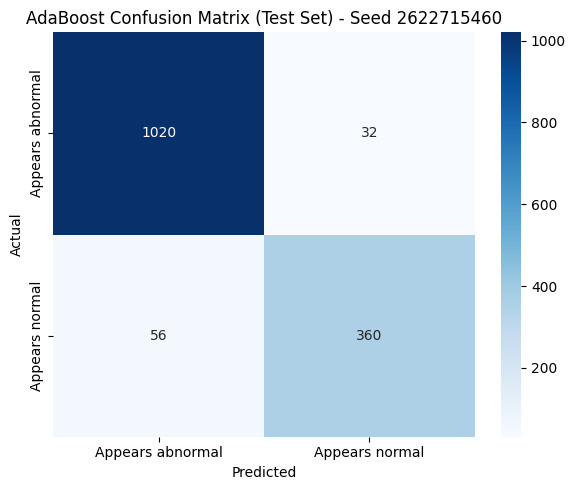


Final MobileNetV2 Test Loss: 0.3904 (CE: 0.2540, Dice: 0.5267), Final MobileNetV2 Test Accuracy: 0.9244

MobileNetV2 Test Precision (weighted): 0.9257
MobileNetV2 Test Recall (weighted): 0.9244
MobileNetV2 Test F1-score (weighted): 0.9220

MobileNetV2 Per-class report:
                  precision    recall  f1-score   support

Appears abnormal     0.9182    0.9819    0.9490      1052
  Appears normal     0.9446    0.7788    0.8538       416

        accuracy                         0.9244      1468
       macro avg     0.9314    0.8804    0.9014      1468
    weighted avg     0.9257    0.9244    0.9220      1468



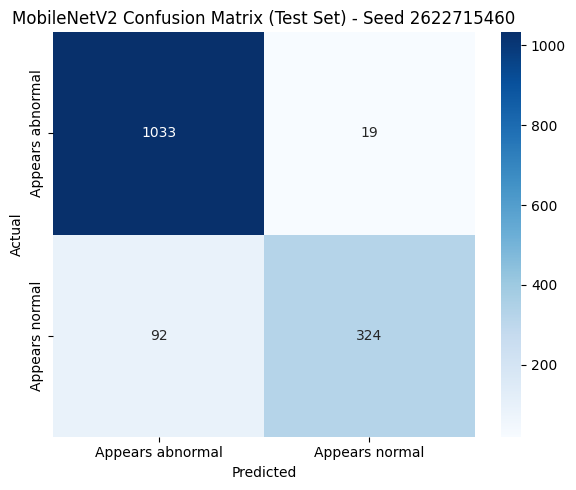

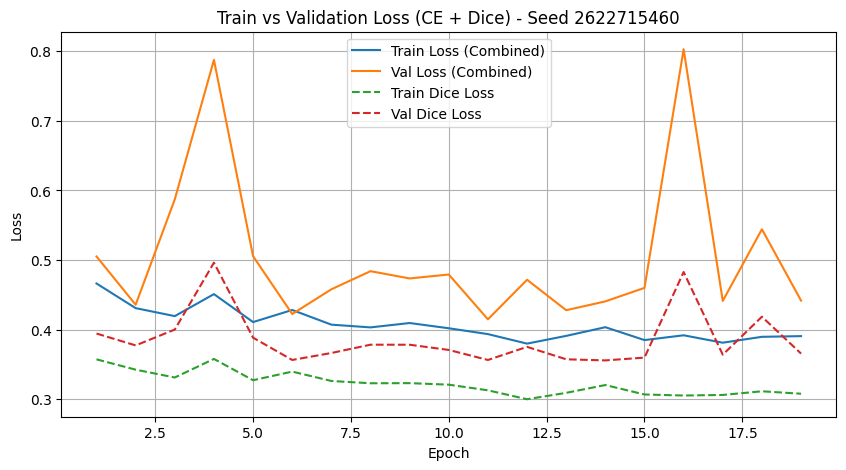

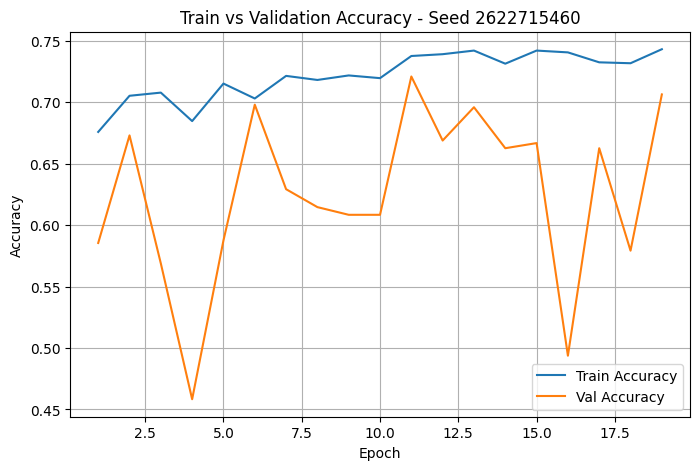


================ FINAL SUMMARY ================
Seed: 2622715460
Best MobileNetV2 Val Accuracy: 0.7208
MobileNetV2 Test Accuracy: 0.9244
MobileNetV2 Test Precision: 0.9257
MobileNetV2 Test Recall: 0.9244
MobileNetV2 Test F1-score: 0.9220
MobileNetV2 Test Dice Loss: 0.5267

---------------- AdaBoost ----------------
AdaBoost Validation Accuracy: 0.6729
AdaBoost Test Accuracy: 0.9401
AdaBoost Test Precision: 0.9396
AdaBoost Test Recall: 0.9401
AdaBoost Test F1-score: 0.9395


/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=MobileNet_V2_Weights.IMAGENET1K_V1`. You can also use `weights=MobileNet_V2_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)




########## SEED = 512 ##########

Saved split indices: 2720 train / 480 val


100%|██████████| 43/43 [00:19<00:00,  2.23it/s]


Epoch [1/50] Train Loss: 0.4737 (CE: 0.5890, Dice: 0.3584), Train Acc: 0.6754 | Val Loss: 0.4919 (CE: 0.5954, Dice: 0.3884), Val Acc: 0.6208
  -> Saving best model (Val Accuracy: 0.6208)


...

Epoch [10/50] Train Loss: 0.3962 (CE: 0.4799, Dice: 0.3126), Train Acc: 0.7349 | Val Loss: 0.4258 (CE: 0.5099, Dice: 0.3418), Val Acc: 0.6875
  -> No improvement for 7/8 epochs


100%|██████████| 43/43 [00:19<00:00,  2.24it/s]
/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=None`.
  warnings.warn(msg)


Epoch [11/50] Train Loss: 0.3882 (CE: 0.4705, Dice: 0.3059), Train Acc: 0.7386 | Val Loss: 0.4220 (CE: 0.4877, Dice: 0.3563), Val Acc: 0.6937
  -> No improvement for 8/8 epochs

Early stopping triggered at epoch 11. Best Val Accuracy: 0.7125
Saved model weights -> /kaggle/working/mobilenetv2_final_weights_seed512.pth

Extracting MobileNetV2 features...


Extracting Features: 100%|██████████| 23/23 [00:05<00:00,  4.22it/s]



Feature shape: (2720, 1280)

Training AdaBoost...
Saved AdaBoost -> /kaggle/working/adaboost_final_seed512.joblib

AdaBoost Validation Accuracy: 0.6562
AdaBoost Test Accuracy: 0.8999

---------------- AdaBoost Metrics ----------------
AdaBoost Test Accuracy: 0.8999
AdaBoost Test Precision (weighted): 0.9000
AdaBoost Test Recall (weighted): 0.8999
AdaBoost Test F1-score (weighted): 0.8963

AdaBoost Per-class report:
                  precision    recall  f1-score   support

Appears abnormal     0.8994    0.9686    0.9327      1052
  Appears normal     0.9015    0.7260    0.8043       416

        accuracy                         0.8999      1468
       macro avg     0.9004    0.8473    0.8685      1468
    weighted avg     0.9000    0.8999    0.8963      1468



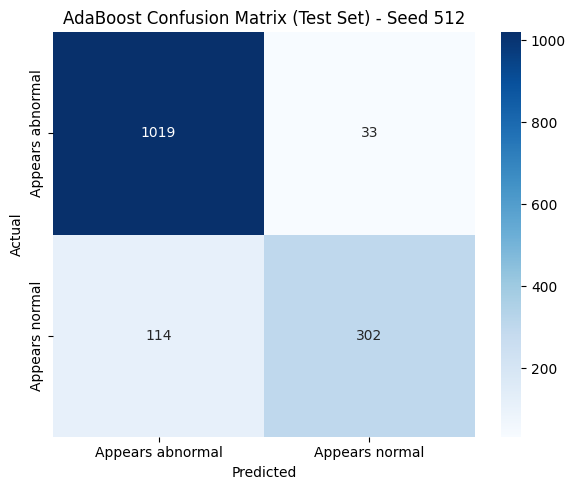


Final MobileNetV2 Test Loss: 0.4190 (CE: 0.3098, Dice: 0.5283), Final MobileNetV2 Test Accuracy: 0.8583

MobileNetV2 Test Precision (weighted): 0.8576
MobileNetV2 Test Recall (weighted): 0.8583
MobileNetV2 Test F1-score (weighted): 0.8502

MobileNetV2 Per-class report:
                  precision    recall  f1-score   support

Appears abnormal     0.8601    0.9582    0.9065      1052
  Appears normal     0.8514    0.6058    0.7079       416

        accuracy                         0.8583      1468
       macro avg     0.8557    0.7820    0.8072      1468
    weighted avg     0.8576    0.8583    0.8502      1468



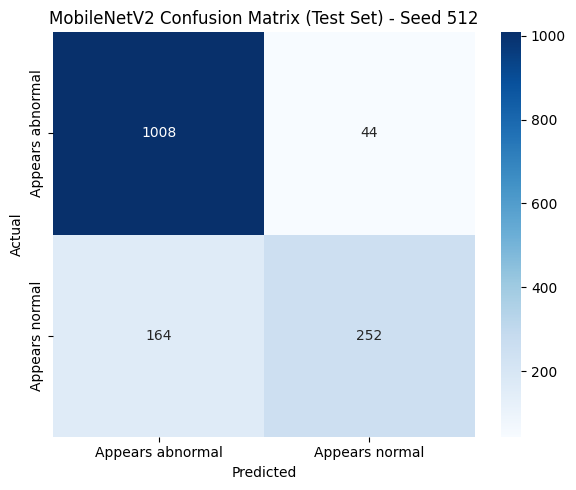

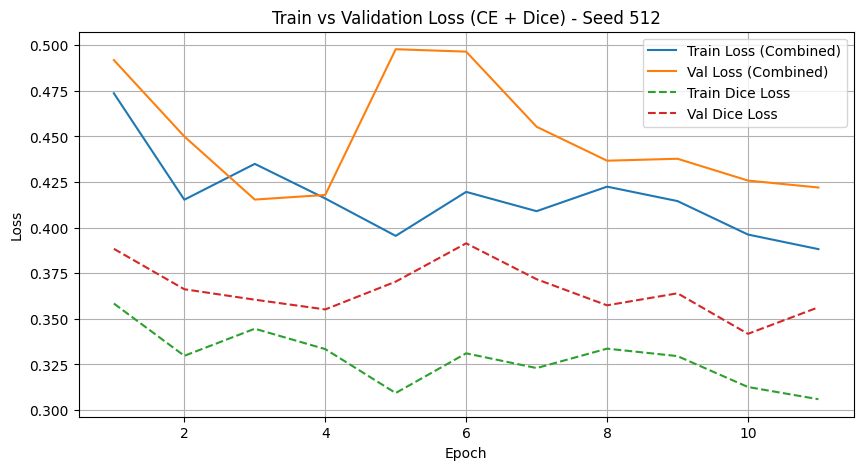

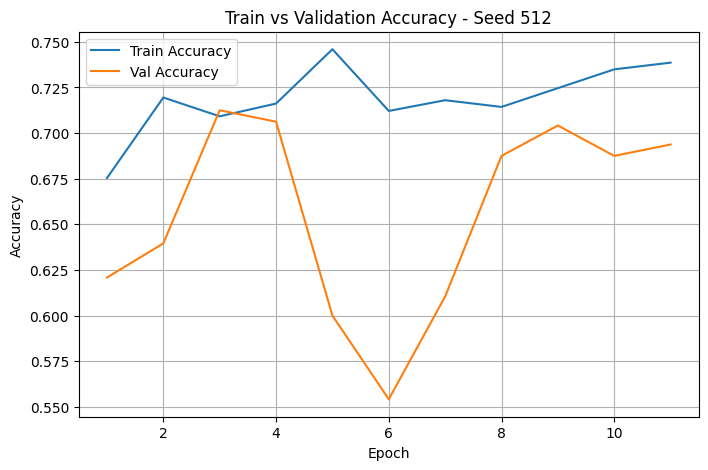


================ FINAL SUMMARY ================
Seed: 512
Best MobileNetV2 Val Accuracy: 0.7125
MobileNetV2 Test Accuracy: 0.8583
MobileNetV2 Test Precision: 0.8576
MobileNetV2 Test Recall: 0.8583
MobileNetV2 Test F1-score: 0.8502
MobileNetV2 Test Dice Loss: 0.5283

---------------- AdaBoost ----------------
AdaBoost Validation Accuracy: 0.6562
AdaBoost Test Accuracy: 0.8999
AdaBoost Test Precision: 0.9000
AdaBoost Test Recall: 0.8999
AdaBoost Test F1-score: 0.8963


/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=MobileNet_V2_Weights.IMAGENET1K_V1`. You can also use `weights=MobileNet_V2_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)




########## SEED = 2 ##########

Saved split indices: 2720 train / 480 val


100%|██████████| 43/43 [00:19<00:00,  2.24it/s]


Epoch [1/50] Train Loss: 0.4839 (CE: 0.5943, Dice: 0.3734), Train Acc: 0.6518 | Val Loss: 0.5283 (CE: 0.6524, Dice: 0.4041), Val Acc: 0.5542
  -> Saving best model (Val Accuracy: 0.5542)


...

Epoch [21/50] Train Loss: 0.3833 (CE: 0.4602, Dice: 0.3064), Train Acc: 0.7360 | Val Loss: 0.4428 (CE: 0.5166, Dice: 0.3690), Val Acc: 0.6813
  -> No improvement for 7/8 epochs


100%|██████████| 43/43 [00:19<00:00,  2.25it/s]
/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=None`.
  warnings.warn(msg)


Epoch [22/50] Train Loss: 0.3909 (CE: 0.4746, Dice: 0.3072), Train Acc: 0.7474 | Val Loss: 0.4550 (CE: 0.5566, Dice: 0.3534), Val Acc: 0.6479
  -> No improvement for 8/8 epochs

Early stopping triggered at epoch 22. Best Val Accuracy: 0.7750
Saved model weights -> /kaggle/working/mobilenetv2_final_weights_seed2.pth

Extracting MobileNetV2 features...


Extracting Features: 100%|██████████| 23/23 [00:05<00:00,  4.20it/s]



Feature shape: (2720, 1280)

Training AdaBoost...
Saved AdaBoost -> /kaggle/working/adaboost_final_seed2.joblib

AdaBoost Validation Accuracy: 0.6354
AdaBoost Test Accuracy: 0.9114

---------------- AdaBoost Metrics ----------------
AdaBoost Test Accuracy: 0.9114
AdaBoost Test Precision (weighted): 0.9104
AdaBoost Test Recall (weighted): 0.9114
AdaBoost Test F1-score (weighted): 0.9097

AdaBoost Per-class report:
                  precision    recall  f1-score   support

Appears abnormal     0.9191    0.9610    0.9396      1052
  Appears normal     0.8886    0.7861    0.8342       416

        accuracy                         0.9114      1468
       macro avg     0.9038    0.8735    0.8869      1468
    weighted avg     0.9104    0.9114    0.9097      1468



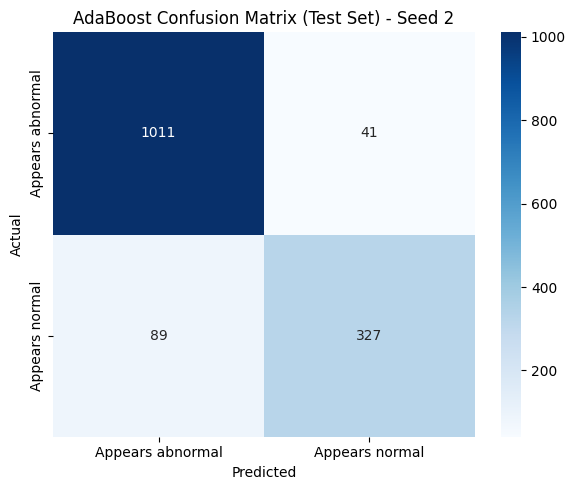


Final MobileNetV2 Test Loss: 0.3984 (CE: 0.2722, Dice: 0.5245), Final MobileNetV2 Test Accuracy: 0.8862

MobileNetV2 Test Precision (weighted): 0.8907
MobileNetV2 Test Recall (weighted): 0.8862
MobileNetV2 Test F1-score (weighted): 0.8794

MobileNetV2 Per-class report:
                  precision    recall  f1-score   support

Appears abnormal     0.8760    0.9800    0.9251      1052
  Appears normal     0.9278    0.6490    0.7638       416

        accuracy                         0.8862      1468
       macro avg     0.9019    0.8145    0.8444      1468
    weighted avg     0.8907    0.8862    0.8794      1468



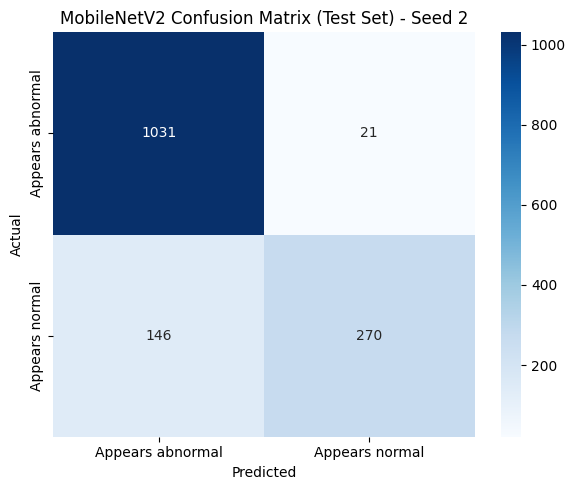

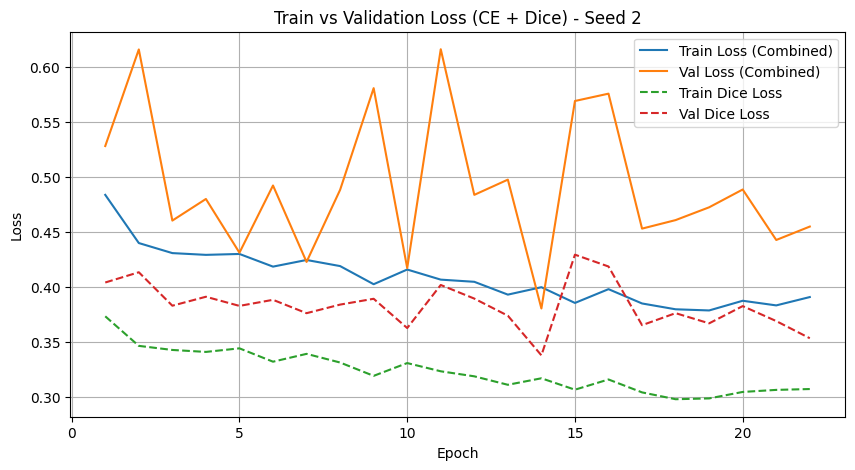

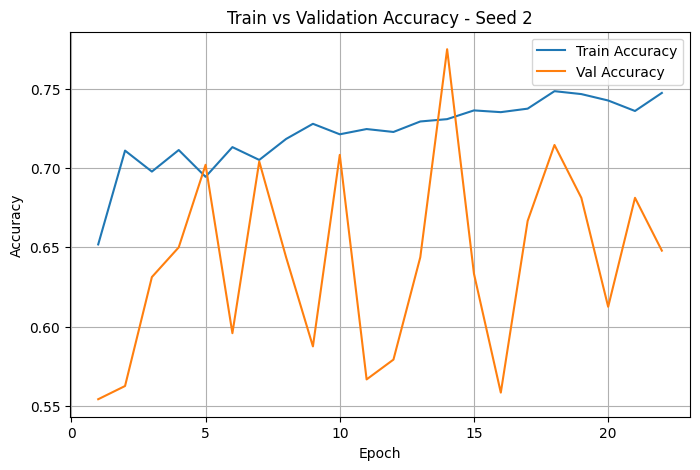


================ FINAL SUMMARY ================
Seed: 2
Best MobileNetV2 Val Accuracy: 0.7750
MobileNetV2 Test Accuracy: 0.8862
MobileNetV2 Test Precision: 0.8907
MobileNetV2 Test Recall: 0.8862
MobileNetV2 Test F1-score: 0.8794
MobileNetV2 Test Dice Loss: 0.5245

---------------- AdaBoost ----------------
AdaBoost Validation Accuracy: 0.6354
AdaBoost Test Accuracy: 0.9114
AdaBoost Test Precision: 0.9104
AdaBoost Test Recall: 0.9114
AdaBoost Test F1-score: 0.9097


=========================== PER-SEED RESULTS ===========================
Metric                             Seed 2622715460          Seed 512            Seed 2
--------------------------------------------------------------------------------------
MobileNetV2 Best Val Accuracy               0.7208            0.7125            0.7750
MobileNetV2 Test Accuracy                   0.9244            0.8583            0.8862
MobileNetV2 Test Precision                  0.9257            0.8576            0.8907
MobileNetV2 Test Reca

In [4]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import DataLoader, WeightedRandomSampler, random_split
from torchvision import datasets, transforms, models
from tqdm import tqdm
import numpy as np
import os
import json
import joblib
import random
import gc
import matplotlib.pyplot as plt

from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

from sklearn.ensemble import AdaBoostClassifier

import seaborn as sns


# ============================================================
# Seeds for the 3-seed experiment (fixed in advance)
#   Seed 1 = same as the original single-seed run
#   Seed 2 = 512
#   Seed 3 = 2
# ============================================================
SEEDS = [2622715460, 512, 2]


# ============================================================
# Device configuration
# ============================================================
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)


# ============================================================
# Paths to train and test datasets
# ============================================================
train_dir = '/kaggle/working/PCOSGen-train/train'
test_dir = '/kaggle/working/PCOSGen-train/test'
OUT_DIR = '/kaggle/working'


# ============================================================
# Image transformations
# ============================================================
train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(20),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

test_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])


# ============================================================
# Dice Loss
# ============================================================
class DiceLoss(nn.Module):

    def __init__(self, num_classes, smooth=1e-6):
        super().__init__()
        self.num_classes = num_classes
        self.smooth = smooth

    def forward(self, logits, targets):
        probs = F.softmax(logits, dim=1)

        targets_one_hot = F.one_hot(
            targets,
            num_classes=self.num_classes
        ).float()

        intersection = (probs * targets_one_hot).sum(dim=0)

        union = probs.sum(dim=0) + targets_one_hot.sum(dim=0)

        dice_score = (2. * intersection + self.smooth) / (union + self.smooth)

        dice_loss = 1. - dice_score.mean()

        return dice_loss


# ============================================================
# Combined CrossEntropy + Dice Loss
# ============================================================
class CombinedLoss(nn.Module):

    def __init__(self, num_classes, ce_weight=0.5, dice_weight=0.5):
        super().__init__()
        self.ce_loss = nn.CrossEntropyLoss()
        self.dice_loss = DiceLoss(num_classes)
        self.ce_weight = ce_weight
        self.dice_weight = dice_weight

    def forward(self, logits, targets):
        ce = self.ce_loss(logits, targets)
        dice = self.dice_loss(logits, targets)
        total = self.ce_weight * ce + self.dice_weight * dice
        return total, ce, dice


# ============================================================
# Function to evaluate MobileNetV2
# ============================================================
def evaluate_model(model, loader, criterion):

    model.eval()

    correct = 0
    total = 0

    running_loss = 0.0
    running_ce = 0.0
    running_dice = 0.0

    with torch.no_grad():

        for images, labels in loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)

            loss, ce, dice = criterion(outputs, labels)

            running_loss += loss.item()
            running_ce += ce.item()
            running_dice += dice.item()

            _, predicted = torch.max(outputs, 1)

            total += labels.size(0)

            correct += (predicted == labels).sum().item()

    accuracy = correct / total

    n = len(loader)

    return (
        accuracy,
        running_loss / n,
        running_ce / n,
        running_dice / n
    )


# ============================================================
# Get predictions
# ============================================================
def get_predictions(model, loader):

    model.eval()

    all_preds = []
    all_labels = []

    with torch.no_grad():

        for images, labels in loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)

            _, predicted = torch.max(outputs, 1)

            all_preds.extend(predicted.cpu().numpy())

            all_labels.extend(labels.cpu().numpy())

    return all_labels, all_preds


# ============================================================
# Feature extraction (MobileNetV2 -> GAP -> flatten)
# ============================================================
def extract_features(model, loader):

    model.eval()

    features = []
    labels_list = []

    with torch.no_grad():

        for images, labels in tqdm(loader, desc="Extracting Features"):

            images = images.to(device)

            # Extract features before classifier
            x = model.features(images)

            # Global Average Pooling
            x = F.adaptive_avg_pool2d(x, (1, 1))

            # Flatten
            x = torch.flatten(x, 1)

            features.extend(x.cpu().numpy())

            labels_list.extend(labels.numpy())

    return (
        np.array(features),
        np.array(labels_list)
    )


# ============================================================
# ONE FULL EXPERIMENT FOR ONE SEED
# (identical pipeline to the original single-seed script)
# ============================================================
def run_experiment(seed):

    print(f"\n\n########## SEED = {seed} ##########\n")

    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

    # ---------------- Datasets ----------------
    train_dataset = datasets.ImageFolder(
        train_dir,
        transform=train_transform
    )

    test_dataset = datasets.ImageFolder(
        test_dir,
        transform=test_transform
    )

    # ---------------- Split train into train + val (85/15) ----------------
    val_size = int(0.15 * len(train_dataset))

    train_size = len(train_dataset) - val_size

    train_subset, val_subset = random_split(
        train_dataset,
        [train_size, val_size]
    )

    # ---------------- Save train / val indices ----------------
    split_info = {
        "seed": seed,
        "val_fraction": 0.15,
        "classes": train_dataset.classes,
        "class_to_idx": train_dataset.class_to_idx,
        "train_indices": [int(i) for i in train_subset.indices],
        "val_indices": [int(i) for i in val_subset.indices],
        "train_files": [train_dataset.samples[i][0] for i in train_subset.indices],
        "val_files": [train_dataset.samples[i][0] for i in val_subset.indices],
    }
    with open(os.path.join(OUT_DIR, f"split_indices_seed{seed}.json"), "w") as f:
        json.dump(split_info, f)
    print(f"Saved split indices: {len(train_subset.indices)} train / {len(val_subset.indices)} val")

    # ---------------- Class weights + sampler ----------------
    train_targets = [
        train_dataset.targets[i]
        for i in train_subset.indices
    ]

    class_counts = np.bincount(
        train_targets
    )

    class_weights = 1. / class_counts

    sample_weights = [
        class_weights[label]
        for label in train_targets
    ]

    sampler = WeightedRandomSampler(
        weights=sample_weights,
        num_samples=len(train_subset),
        replacement=True
    )

    # ---------------- DataLoaders ----------------
    train_loader = DataLoader(
        train_subset,
        batch_size=64,
        sampler=sampler
    )

    val_loader = DataLoader(
        val_subset,
        batch_size=64,
        shuffle=False
    )

    test_loader = DataLoader(
        test_dataset,
        batch_size=64,
        shuffle=False
    )

    # ---------------- Load pre-trained MobileNetV2 ----------------
    mobilenet = models.mobilenet_v2(
        pretrained=True
    )

    num_classes = len(
        train_dataset.classes
    )

    mobilenet.classifier[1] = nn.Linear(
        mobilenet.classifier[1].in_features,
        num_classes
    )

    mobilenet = mobilenet.to(device)

    criterion = CombinedLoss(
        num_classes=num_classes,
        ce_weight=0.5,
        dice_weight=0.5
    )

    optimizer = optim.Adam(
        mobilenet.parameters(),
        lr=0.001
    )

    # ---------------- Early stopping setup ----------------
    best_accuracy = 0.0

    best_model_path = f"Mobilenet_seed{seed}.pkl"

    patience = 8

    epochs_no_improve = 0

    max_epochs = 50

    # ---------------- Lists for graphs ----------------
    train_losses = []
    train_accs = []

    val_losses = []
    val_accs = []

    train_ce_losses = []
    train_dice_losses = []

    val_ce_losses = []
    val_dice_losses = []

    # ---------------- MobileNetV2 Training ----------------
    for epoch in range(max_epochs):

        mobilenet.train()

        running_loss = 0.0
        running_ce = 0.0
        running_dice = 0.0

        correct_train = 0
        total_train = 0

        for images, labels in tqdm(train_loader):

            images = images.to(device)
            labels = labels.to(device)

            outputs = mobilenet(images)

            loss, ce, dice = criterion(outputs, labels)

            optimizer.zero_grad()

            loss.backward()

            optimizer.step()

            running_loss += loss.item()
            running_ce += ce.item()
            running_dice += dice.item()

            _, predicted = torch.max(outputs, 1)

            total_train += labels.size(0)

            correct_train += (predicted == labels).sum().item()

        train_accuracy = correct_train / total_train

        n_batches = len(train_loader)

        train_loss = running_loss / n_batches
        train_ce = running_ce / n_batches
        train_dice = running_dice / n_batches

        # ---------------- Validation ----------------
        val_accuracy, val_loss, val_ce, val_dice = evaluate_model(
            mobilenet,
            val_loader,
            criterion
        )

        # ---------------- Store values for graphs ----------------
        train_losses.append(train_loss)
        train_accs.append(train_accuracy)
        val_losses.append(val_loss)
        val_accs.append(val_accuracy)
        train_ce_losses.append(train_ce)
        train_dice_losses.append(train_dice)
        val_ce_losses.append(val_ce)
        val_dice_losses.append(val_dice)

        # ---------------- Print epoch results ----------------
        print(
            f'Epoch [{epoch+1}/{max_epochs}] '
            f'Train Loss: {train_loss:.4f} '
            f'(CE: {train_ce:.4f}, '
            f'Dice: {train_dice:.4f}), '
            f'Train Acc: {train_accuracy:.4f} | '
            f'Val Loss: {val_loss:.4f} '
            f'(CE: {val_ce:.4f}, '
            f'Dice: {val_dice:.4f}), '
            f'Val Acc: {val_accuracy:.4f}'
        )

        # ---------------- Early stopping logic ----------------
        if val_accuracy > best_accuracy:

            best_accuracy = val_accuracy

            epochs_no_improve = 0

            print(
                f'  -> Saving best model '
                f'(Val Accuracy: {best_accuracy:.4f})'
            )

            torch.save(mobilenet.state_dict(), best_model_path)

        else:

            epochs_no_improve += 1

            print(
                f'  -> No improvement for '
                f'{epochs_no_improve}/{patience} epochs'
            )

        if epochs_no_improve >= patience:

            print(
                f'\nEarly stopping triggered at '
                f'epoch {epoch+1}. '
                f'Best Val Accuracy: {best_accuracy:.4f}'
            )

            break

    # ---------------- Load the best MobileNetV2 model ----------------
    best_mobilenet_model = models.mobilenet_v2(
        pretrained=False
    )

    best_mobilenet_model.classifier[1] = nn.Linear(
        mobilenet.classifier[1].in_features,
        num_classes
    )

    best_mobilenet_model = best_mobilenet_model.to(device)

    best_mobilenet_model.load_state_dict(
        torch.load(best_model_path)
    )

    # ---------------- Save final trained MobileNetV2 weights ----------------
    final_weights_path = os.path.join(OUT_DIR, f"mobilenetv2_final_weights_seed{seed}.pth")
    torch.save({
        "state_dict": best_mobilenet_model.state_dict(),
        "num_classes": num_classes,
        "classes": train_dataset.classes,
        "class_to_idx": train_dataset.class_to_idx,
        "best_val_accuracy": best_accuracy,
        "seed": seed,
        "input_size": 224,
        "normalize_mean": [0.485, 0.456, 0.406],
        "normalize_std": [0.229, 0.224, 0.225],
    }, final_weights_path)
    print("Saved model weights ->", final_weights_path)

    # ============================================================
    # ADABOOST: MobileNetV2 Feature Extraction + AdaBoost
    # ============================================================
    print("\nExtracting MobileNetV2 features...")

    train_features, train_labels = extract_features(best_mobilenet_model, train_loader)

    val_features, val_labels = extract_features(best_mobilenet_model, val_loader)

    test_features, test_labels = extract_features(best_mobilenet_model, test_loader)

    print("\nFeature shape:", train_features.shape)

    adaboost_model = AdaBoostClassifier(
        n_estimators=100,
        learning_rate=1.0,
        random_state=seed
    )

    print("\nTraining AdaBoost...")

    adaboost_model.fit(train_features, train_labels)

    adaboost_path = os.path.join(OUT_DIR, f"adaboost_final_seed{seed}.joblib")
    joblib.dump(adaboost_model, adaboost_path)
    print("Saved AdaBoost ->", adaboost_path)

    # ---------------- AdaBoost Validation ----------------
    adaboost_val_preds = adaboost_model.predict(val_features)

    adaboost_val_accuracy = np.mean(adaboost_val_preds == val_labels)

    print(f"\nAdaBoost Validation Accuracy: {adaboost_val_accuracy:.4f}")

    # ---------------- AdaBoost Test Predictions ----------------
    adaboost_test_preds = adaboost_model.predict(test_features)

    adaboost_test_accuracy = np.mean(adaboost_test_preds == test_labels)

    print(f"AdaBoost Test Accuracy: {adaboost_test_accuracy:.4f}")

    # ---------------- AdaBoost Metrics ----------------
    class_names = train_dataset.classes

    adaboost_accuracy = np.mean(adaboost_test_preds == test_labels)

    adaboost_precision = precision_score(
        test_labels, adaboost_test_preds, average='weighted', zero_division=0
    )

    adaboost_recall = recall_score(
        test_labels, adaboost_test_preds, average='weighted', zero_division=0
    )

    adaboost_f1 = f1_score(
        test_labels, adaboost_test_preds, average='weighted', zero_division=0
    )

    print("\n---------------- AdaBoost Metrics ----------------")
    print(f"AdaBoost Test Accuracy: {adaboost_accuracy:.4f}")
    print(f"AdaBoost Test Precision (weighted): {adaboost_precision:.4f}")
    print(f"AdaBoost Test Recall (weighted): {adaboost_recall:.4f}")
    print(f"AdaBoost Test F1-score (weighted): {adaboost_f1:.4f}")

    # ---------------- AdaBoost Classification Report ----------------
    print("\nAdaBoost Per-class report:")

    print(
        classification_report(
            test_labels,
            adaboost_test_preds,
            target_names=class_names,
            digits=4,
            zero_division=0
        )
    )

    # ---------------- AdaBoost Confusion Matrix ----------------
    adaboost_cm = confusion_matrix(test_labels, adaboost_test_preds)

    plt.figure(figsize=(6, 5))

    sns.heatmap(
        adaboost_cm,
        annot=True,
        fmt='d',
        cmap='Blues',
        xticklabels=class_names,
        yticklabels=class_names
    )

    plt.xlabel('Predicted')
    plt.ylabel('Actual')
    plt.title(f'AdaBoost Confusion Matrix (Test Set) - Seed {seed}')
    plt.tight_layout()
    plt.show()

    # ---------------- ORIGINAL MOBILENETV2 TEST EVALUATION ----------------
    test_accuracy, test_loss, test_ce, test_dice = evaluate_model(
        best_mobilenet_model,
        test_loader,
        criterion
    )

    print(
        f'\nFinal MobileNetV2 Test Loss: '
        f'{test_loss:.4f} '
        f'(CE: {test_ce:.4f}, '
        f'Dice: {test_dice:.4f}), '
        f'Final MobileNetV2 Test Accuracy: '
        f'{test_accuracy:.4f}'
    )

    # ---------------- MobileNetV2 Test Metrics ----------------
    true_labels, pred_labels = get_predictions(best_mobilenet_model, test_loader)

    precision = precision_score(true_labels, pred_labels, average='weighted', zero_division=0)

    recall = recall_score(true_labels, pred_labels, average='weighted', zero_division=0)

    f1 = f1_score(true_labels, pred_labels, average='weighted', zero_division=0)

    print(f'\nMobileNetV2 Test Precision (weighted): {precision:.4f}')
    print(f'MobileNetV2 Test Recall (weighted): {recall:.4f}')
    print(f'MobileNetV2 Test F1-score (weighted): {f1:.4f}')

    # ---------------- MobileNetV2 Classification Report ----------------
    print('\nMobileNetV2 Per-class report:')

    print(
        classification_report(
            true_labels,
            pred_labels,
            target_names=class_names,
            digits=4,
            zero_division=0
        )
    )

    # ---------------- MobileNetV2 Confusion Matrix ----------------
    cm = confusion_matrix(true_labels, pred_labels)

    plt.figure(figsize=(6, 5))

    sns.heatmap(
        cm,
        annot=True,
        fmt='d',
        cmap='Blues',
        xticklabels=class_names,
        yticklabels=class_names
    )

    plt.xlabel('Predicted')
    plt.ylabel('Actual')
    plt.title(f'MobileNetV2 Confusion Matrix (Test Set) - Seed {seed}')
    plt.tight_layout()
    plt.show()

    # ---------------- Plot Train vs Val Loss ----------------
    epochs_range = range(1, len(train_losses) + 1)

    plt.figure(figsize=(10, 5))

    plt.plot(epochs_range, train_losses, label='Train Loss (Combined)')
    plt.plot(epochs_range, val_losses, label='Val Loss (Combined)')
    plt.plot(epochs_range, train_dice_losses, '--', label='Train Dice Loss')
    plt.plot(epochs_range, val_dice_losses, '--', label='Val Dice Loss')

    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.title(f'Train vs Validation Loss (CE + Dice) - Seed {seed}')
    plt.legend()
    plt.grid(True)
    plt.show()

    # ---------------- Plot Train vs Val Accuracy ----------------
    plt.figure(figsize=(8, 5))

    plt.plot(epochs_range, train_accs, label='Train Accuracy')
    plt.plot(epochs_range, val_accs, label='Val Accuracy')

    plt.xlabel('Epoch')
    plt.ylabel('Accuracy')
    plt.title(f'Train vs Validation Accuracy - Seed {seed}')
    plt.legend()
    plt.grid(True)
    plt.show()

    # ---------------- FINAL SUMMARY (per seed) ----------------
    print('\n================ FINAL SUMMARY ================')
    print(f'Seed: {seed}')
    print(f'Best MobileNetV2 Val Accuracy: {best_accuracy:.4f}')
    print(f'MobileNetV2 Test Accuracy: {test_accuracy:.4f}')
    print(f'MobileNetV2 Test Precision: {precision:.4f}')
    print(f'MobileNetV2 Test Recall: {recall:.4f}')
    print(f'MobileNetV2 Test F1-score: {f1:.4f}')
    print(f'MobileNetV2 Test Dice Loss: {test_dice:.4f}')

    print('\n---------------- AdaBoost ----------------')
    print(f'AdaBoost Validation Accuracy: {adaboost_val_accuracy:.4f}')
    print(f'AdaBoost Test Accuracy: {adaboost_accuracy:.4f}')
    print(f'AdaBoost Test Precision: {adaboost_precision:.4f}')
    print(f'AdaBoost Test Recall: {adaboost_recall:.4f}')
    print(f'AdaBoost Test F1-score: {adaboost_f1:.4f}')

    result = {
        "seed": seed,
        "epochs_trained": len(train_losses),
        "mobilenet_best_val_acc": float(best_accuracy),
        "mobilenet_test_acc": float(test_accuracy),
        "mobilenet_test_precision": float(precision),
        "mobilenet_test_recall": float(recall),
        "mobilenet_test_f1": float(f1),
        "mobilenet_test_dice_loss": float(test_dice),
        "adaboost_val_acc": float(adaboost_val_accuracy),
        "adaboost_test_acc": float(adaboost_accuracy),
        "adaboost_test_precision": float(adaboost_precision),
        "adaboost_test_recall": float(adaboost_recall),
        "adaboost_test_f1": float(adaboost_f1),
        "mobilenet_confusion_matrix": cm.tolist(),
        "adaboost_confusion_matrix": adaboost_cm.tolist(),
    }

    # free memory before next seed
    del mobilenet, best_mobilenet_model, optimizer, train_loader, val_loader, test_loader
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    return result


# ============================================================
# RUN ALL SEEDS
# ============================================================
all_results = []

for s in SEEDS:
    all_results.append(run_experiment(s))

with open(os.path.join(OUT_DIR, "three_seed_results.json"), "w") as f:
    json.dump(all_results, f, indent=2)


# ============================================================
# AGGREGATE: mean +/- SD over seeds
# (SD = sample standard deviation, ddof=1, n = number of seeds)
# ============================================================
METRICS = [
    ("MobileNetV2 Best Val Accuracy",  "mobilenet_best_val_acc"),
    ("MobileNetV2 Test Accuracy",      "mobilenet_test_acc"),
    ("MobileNetV2 Test Precision",     "mobilenet_test_precision"),
    ("MobileNetV2 Test Recall",        "mobilenet_test_recall"),
    ("MobileNetV2 Test F1-score",      "mobilenet_test_f1"),
    ("MobileNetV2 Test Dice Loss",     "mobilenet_test_dice_loss"),
    ("AdaBoost Validation Accuracy",   "adaboost_val_acc"),
    ("AdaBoost Test Accuracy",         "adaboost_test_acc"),
    ("AdaBoost Test Precision",        "adaboost_test_precision"),
    ("AdaBoost Test Recall",           "adaboost_test_recall"),
    ("AdaBoost Test F1-score",         "adaboost_test_f1"),
]

print('\n\n=========================== PER-SEED RESULTS ===========================')
header = f"{'Metric':<32}" + "".join(f"{('Seed ' + str(r['seed'])):>18}" for r in all_results)
print(header)
print('-' * len(header))
for name, key in METRICS:
    row = f"{name:<32}" + "".join(f"{r[key]:>18.4f}" for r in all_results)
    print(row)

print(f'\n=================== MEAN +/- SD OVER {len(all_results)} SEEDS ===================')
summary = {}
for name, key in METRICS:
    vals = np.array([r[key] for r in all_results], dtype=float)
    mean = vals.mean()
    sd = vals.std(ddof=1) if len(vals) > 1 else 0.0
    summary[key] = {"mean": float(mean), "sd": float(sd), "values": vals.tolist()}
    print(f"{name:<32}: {mean:.4f} +/- {sd:.4f}   "
          f"(min {vals.min():.4f}, max {vals.max():.4f})")

print('\nPercentage form (for the paper):')
for name, key in METRICS:
    if 'Dice' in name:
        continue
    m, s_ = summary[key]['mean'] * 100, summary[key]['sd'] * 100
    print(f"{name:<32}: {m:.2f} +/- {s_:.2f} %")

with open(os.path.join(OUT_DIR, "three_seed_summary_mean_sd.json"), "w") as f:
    json.dump({"seeds": SEEDS, "sd_type": "sample (ddof=1)", "summary": summary}, f, indent=2)

print("\nSaved -> three_seed_results.json, three_seed_summary_mean_sd.json")

# Saving

In [5]:
# ============================================================
# PACKAGE THREE-SEED MobileNetV2 + ADABOOST EXPERIMENT
# Run this cell AFTER the three-seed training script has finished.
# Creates ONE ZIP containing ONE folder per seed (3 folders), each with the
# split, trained models, config, environment info, dataset hashes, README.
# Does NOT retrain anything.
# ============================================================

import os
import csv
import json
import shutil
import hashlib
import platform
import zipfile
from pathlib import Path
from datetime import datetime, timezone

import torch
import torchvision
import numpy as np
import sklearn
import joblib

# ---------------- CONFIGURATION ----------------
OUT_DIR = os.environ.get("PCOS_OUT_DIR", "/kaggle/working")
TRAIN_DIR = os.path.join(OUT_DIR, "PCOSGen-train", "train")
TEST_DIR = os.path.join(OUT_DIR, "PCOSGen-train", "test")

SEEDS = [2622715460, 512, 2]

# Set True if you also want each seed's metrics JSON inside its folder.
INCLUDE_RESULTS = False

ROOT_PACKAGE_NAME = "MobileNetV2_AdaBoost_Three_Seeds"
FOLDER_PREFIX = "MobileNetV2_AdaBoost"
ROOT_PACKAGE_DIR = os.path.join(OUT_DIR, ROOT_PACKAGE_NAME)
ZIP_PATH = os.path.join(OUT_DIR, ROOT_PACKAGE_NAME + ".zip")
RESULTS_JSON = os.path.join(OUT_DIR, "three_seed_results.json")


# Exact filenames written by the three-seed training script.
def seed_files(seed):
    return {
        "split": os.path.join(OUT_DIR, f"split_indices_seed{seed}.json"),
        "weights": os.path.join(OUT_DIR, f"mobilenetv2_final_weights_seed{seed}.pth"),
        "adaboost": os.path.join(OUT_DIR, f"adaboost_final_seed{seed}.joblib"),
        "checkpoint": os.path.join(OUT_DIR, f"Mobilenet_seed{seed}.pkl"),
    }


def sha256_file(path):
    digest = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b""):
            digest.update(chunk)
    return digest.hexdigest()


def write_json(path, data):
    with open(path, "w", encoding="utf-8") as f:
        json.dump(data, f, indent=4)


def create_dataset_manifest(dataset_dir, output_csv):
    if not os.path.isdir(dataset_dir):
        print(f"WARNING: Dataset directory not found; manifest skipped: {dataset_dir}")
        return False
    with open(output_csv, "w", newline="", encoding="utf-8") as f:
        writer = csv.writer(f)
        writer.writerow(["relative_path", "class_name", "file_size_bytes", "sha256"])
        for path in sorted(Path(dataset_dir).rglob("*")):
            if not path.is_file():
                continue
            relative_path = path.relative_to(dataset_dir).as_posix()
            parts = Path(relative_path).parts
            class_name = parts[0] if len(parts) > 1 else ""
            writer.writerow([relative_path, class_name, path.stat().st_size, sha256_file(path)])
    return True


# ---------------- VALIDATE INPUTS ----------------
missing = []
for seed in SEEDS:
    paths = seed_files(seed)
    for key in ("split", "weights", "adaboost"):
        if not os.path.isfile(paths[key]):
            missing.append(f"Seed {seed} [{key}]: {paths[key]}")

if missing:
    raise FileNotFoundError(
        "Cannot package all three seeds. Required files are missing:\n- "
        + "\n- ".join(missing)
        + "\nRun the three-seed training script (the version that SAVES split, "
          "weights and AdaBoost) and confirm these files exist."
    )

# ---------------- CLEAN PACKAGE DIRECTORY ----------------
if os.path.exists(ROOT_PACKAGE_DIR):
    shutil.rmtree(ROOT_PACKAGE_DIR)
os.makedirs(ROOT_PACKAGE_DIR, exist_ok=True)

# ---------------- SHARED ENVIRONMENT METADATA ----------------
environment = {
    "created_utc": datetime.now(timezone.utc).isoformat(),
    "python_version": platform.python_version(),
    "platform": platform.platform(),
    "pytorch_version": str(torch.__version__),
    "torchvision_version": str(torchvision.__version__),
    "numpy_version": np.__version__,
    "scikit_learn_version": sklearn.__version__,
    "joblib_version": joblib.__version__,
    "cuda_available": torch.cuda.is_available(),
    "cuda_version": torch.version.cuda,
    "gpu_name": torch.cuda.get_device_name(0) if torch.cuda.is_available() else None,
}

# ---------------- DATASET MANIFESTS (hashed ONCE, copied into each seed) ----------------
manifest_tmp = os.path.join(OUT_DIR, "_manifest_tmp_" + ROOT_PACKAGE_NAME)
if os.path.exists(manifest_tmp):
    shutil.rmtree(manifest_tmp)
os.makedirs(manifest_tmp, exist_ok=True)
print("Hashing dataset files (done once)...")
create_dataset_manifest(TRAIN_DIR, os.path.join(manifest_tmp, "train_dataset_manifest.csv"))
create_dataset_manifest(TEST_DIR, os.path.join(manifest_tmp, "test_dataset_manifest.csv"))

all_results = None
if INCLUDE_RESULTS and os.path.isfile(RESULTS_JSON):
    with open(RESULTS_JSON, "r", encoding="utf-8") as f:
        all_results = json.load(f)

# ---------------- BUILD EACH SEED FOLDER ----------------
for seed in SEEDS:
    paths = seed_files(seed)
    folder_name = f"{FOLDER_PREFIX}_Seed_{seed}"
    package_dir = os.path.join(ROOT_PACKAGE_DIR, folder_name)

    for subfolder in ("splits", "models", "config", "metadata"):
        os.makedirs(os.path.join(package_dir, subfolder), exist_ok=True)

    # ----- split: read + validate -----
    with open(paths["split"], "r", encoding="utf-8") as f:
        split_info = json.load(f)

    if int(split_info.get("seed", -1)) != seed:
        raise ValueError(
            f"Seed mismatch in {paths['split']}: found {split_info.get('seed')}, expected {seed}"
        )
    for split_name in ("train", "val"):
        if len(split_info.get(f"{split_name}_indices", [])) != len(
            split_info.get(f"{split_name}_files", [])
        ):
            raise ValueError(f"Seed {seed}: {split_name} index/file count mismatch.")
    if set(split_info["train_indices"]) & set(split_info["val_indices"]):
        raise ValueError(f"Seed {seed}: train/validation indices overlap.")

    shutil.copy2(paths["split"], os.path.join(package_dir, "splits", "split_indices.json"))
    with open(os.path.join(package_dir, "splits", "split_images.csv"),
              "w", newline="", encoding="utf-8") as f:
        writer = csv.writer(f)
        writer.writerow(["split", "dataset_index", "image_name", "image_path", "class_name"])
        for split_name in ("train", "val"):
            for index, image_path in zip(
                split_info[f"{split_name}_indices"], split_info[f"{split_name}_files"]
            ):
                writer.writerow([
                    split_name, index, os.path.basename(image_path), image_path,
                    os.path.basename(os.path.dirname(image_path)),
                ])

    # ----- models -----
    weights_name = os.path.basename(paths["weights"])
    adaboost_name = os.path.basename(paths["adaboost"])
    shutil.copy2(paths["weights"], os.path.join(package_dir, "models", weights_name))
    shutil.copy2(paths["adaboost"], os.path.join(package_dir, "models", adaboost_name))

    checkpoint_name = None
    if os.path.isfile(paths["checkpoint"]):
        checkpoint_name = os.path.basename(paths["checkpoint"])
        shutil.copy2(paths["checkpoint"], os.path.join(package_dir, "models", checkpoint_name))

    # ----- config (read from the saved files, nothing hard-coded that could be wrong) -----
    checkpoint = torch.load(paths["weights"], map_location="cpu", weights_only=False)
    adaboost_model = joblib.load(paths["adaboost"])

    config = {
        "project": "PCOS ultrasound image classification",
        "architecture": "MobileNetV2 feature extractor + AdaBoost",
        "seed": seed,
        "dataset_split": {
            "method": "random_split",
            "validation_fraction": split_info.get("val_fraction", 0.15),
            "train_count": len(split_info["train_indices"]),
            "validation_count": len(split_info["val_indices"]),
            "indices_file": "splits/split_indices.json",
            "image_manifest": "splits/split_images.csv",
        },
        "classes": split_info["classes"],
        "class_to_idx": split_info["class_to_idx"],
        "cnn": {
            "name": "MobileNetV2",
            "weights_file": f"models/{weights_name}",
            "best_checkpoint_file": f"models/{checkpoint_name}" if checkpoint_name else None,
            "num_classes": checkpoint["num_classes"],
            "best_validation_accuracy": checkpoint["best_val_accuracy"],
            "input_size": checkpoint["input_size"],
            "normalization_mean": checkpoint["normalize_mean"],
            "normalization_std": checkpoint["normalize_std"],
            "optimizer": "Adam",
            "learning_rate": 0.001,
            "batch_size": 64,
            "max_epochs": 50,
            "early_stopping_patience": 8,
            "loss": "0.5 * CrossEntropyLoss + 0.5 * DiceLoss",
            "sampler": "WeightedRandomSampler (inverse class frequency)",
            "training_augmentations": [
                "Resize(224, 224)", "RandomHorizontalFlip", "RandomRotation(20)"
            ],
            "feature_extraction": "model.features -> global average pooling -> flatten",
        },
        "adaboost": {
            "model_file": f"models/{adaboost_name}",
            "n_estimators": getattr(adaboost_model, "n_estimators", None),
            "learning_rate": getattr(adaboost_model, "learning_rate", None),
            "random_state": getattr(adaboost_model, "random_state", None),
        },
        "original_kaggle_paths": {"train": TRAIN_DIR, "test": TEST_DIR},
        "note": (
            "Paths refer to the original Kaggle environment. Restore the saved split, "
            "preserve ImageFolder class ordering and preprocessing."
        ),
    }
    write_json(os.path.join(package_dir, "config", "model_config.json"), config)

    seed_environment = dict(environment)
    seed_environment["seed"] = int(seed)
    write_json(os.path.join(package_dir, "metadata", "environment.json"), seed_environment)

    for manifest_name in ("train_dataset_manifest.csv", "test_dataset_manifest.csv"):
        src = os.path.join(manifest_tmp, manifest_name)
        if os.path.isfile(src):
            shutil.copy2(src, os.path.join(package_dir, "metadata", manifest_name))

    # ----- optional per-seed results -----
    if all_results is not None:
        seed_result = next((r for r in all_results if int(r.get("seed", -1)) == seed), None)
        if seed_result is not None:
            os.makedirs(os.path.join(package_dir, "results"), exist_ok=True)
            write_json(os.path.join(package_dir, "results", "seed_results.json"), seed_result)

    # ----- hashes of everything in this seed folder (except the hash file itself) -----
    hashes = {}
    for file_path in sorted(Path(package_dir).rglob("*")):
        if file_path.is_file():
            hashes[file_path.relative_to(package_dir).as_posix()] = sha256_file(file_path)
    write_json(os.path.join(package_dir, "metadata", "artifact_sha256.json"), hashes)

    readme = f"""{folder_name}
{'=' * len(folder_name)}

CONTENTS
--------
splits/split_indices.json
    Exact train/validation indices, image paths, seed and class mapping.
splits/split_images.csv
    Train/validation image manifest with class names.
models/{weights_name}
    Final trained MobileNetV2 weights + inference settings.
models/{adaboost_name}
    Trained AdaBoost classifier (on MobileNetV2 features).
models/{checkpoint_name or '(best checkpoint not found)'}
    Best-validation training checkpoint.
config/model_config.json
    Architecture, preprocessing and training configuration.
metadata/environment.json
    Python, library, platform and CUDA information.
metadata/train_dataset_manifest.csv, metadata/test_dataset_manifest.csv
    Dataset file paths, sizes and SHA-256 hashes.
metadata/artifact_sha256.json
    SHA-256 hashes of every file in this seed folder.

REPRODUCTION NOTES
------------------
1. Use the same dataset version, image files and labels (verify with the manifests).
2. Restore the saved train/validation split; do not create a new split.
3. Preserve ImageFolder class ordering and preprocessing.
4. Load the saved models for inference, or re-run the training notebook with this seed.
5. A matching seed alone does not guarantee bit-identical results across hardware
   or software versions.

IMPORTANT
---------
The dataset images and the training notebook are not included.
Absolute paths refer to the original Kaggle environment.
Metrics/result files are {'included' if all_results is not None else 'NOT included'} in this package.
"""
    with open(os.path.join(package_dir, "README.txt"), "w", encoding="utf-8") as f:
        f.write(readme.strip() + "\n")

    print(
        f"Prepared seed {seed}: {len(split_info['train_indices'])} train / "
        f"{len(split_info['val_indices'])} validation images"
    )

shutil.rmtree(manifest_tmp, ignore_errors=True)

# ---------------- ROOT README ----------------
root_readme = f"""MobileNetV2 + AdaBoost: Three-Seed Reproducibility Package

One folder per seed:
""" + "\n".join(f"- {FOLDER_PREFIX}_Seed_{s}" for s in SEEDS) + """

Each folder holds that seed's split, trained models, configuration,
environment metadata, dataset hashes, artifact hashes and a README.
The dataset images and the training notebook are not included.
"""
with open(os.path.join(ROOT_PACKAGE_DIR, "README.txt"), "w", encoding="utf-8") as f:
    f.write(root_readme)

# ---------------- CREATE ZIP ----------------
if os.path.exists(ZIP_PATH):
    os.remove(ZIP_PATH)

with zipfile.ZipFile(ZIP_PATH, "w", compression=zipfile.ZIP_DEFLATED) as archive:
    for path in sorted(Path(ROOT_PACKAGE_DIR).rglob("*")):
        if path.is_file():
            archive.write(path, arcname=path.relative_to(OUT_DIR).as_posix())

# ---------------- VERIFY ZIP ----------------
with zipfile.ZipFile(ZIP_PATH, "r") as archive:
    bad_file = archive.testzip()
    if bad_file is not None:
        raise RuntimeError(f"ZIP verification failed: {bad_file}")
    names = archive.namelist()

for seed in SEEDS:
    prefix = f"{ROOT_PACKAGE_NAME}/{FOLDER_PREFIX}_Seed_{seed}/"
    if not any(n.startswith(prefix) for n in names):
        raise RuntimeError(f"Seed folder missing from ZIP: {prefix}")

print("\nZIP CREATED AND VERIFIED SUCCESSFULLY")
print("File:", ZIP_PATH)
print("Size: {:.2f} MB".format(os.path.getsize(ZIP_PATH) / (1024 ** 2)))
print("\nZIP CONTENTS:")
for n in names:
    print(" -", n)

Hashing dataset files (done once)...
Prepared seed 2622715460: 2720 train / 480 validation images
Prepared seed 512: 2720 train / 480 validation images
Prepared seed 2: 2720 train / 480 validation images

ZIP CREATED AND VERIFIED SUCCESSFULLY
File: /kaggle/working/MobileNetV2_AdaBoost_Three_Seeds.zip
Size: 49.00 MB

ZIP CONTENTS:
 - MobileNetV2_AdaBoost_Three_Seeds/MobileNetV2_AdaBoost_Seed_2/README.txt
 - MobileNetV2_AdaBoost_Three_Seeds/MobileNetV2_AdaBoost_Seed_2/config/model_config.json
 - MobileNetV2_AdaBoost_Three_Seeds/MobileNetV2_AdaBoost_Seed_2/metadata/artifact_sha256.json
 - MobileNetV2_AdaBoost_Three_Seeds/MobileNetV2_AdaBoost_Seed_2/metadata/environment.json
 - MobileNetV2_AdaBoost_Three_Seeds/MobileNetV2_AdaBoost_Seed_2/metadata/test_dataset_manifest.csv
 - MobileNetV2_AdaBoost_Three_Seeds/MobileNetV2_AdaBoost_Seed_2/metadata/train_dataset_manifest.csv
 - MobileNetV2_AdaBoost_Three_Seeds/MobileNetV2_AdaBoost_Seed_2/models/Mobilenet_seed2.pkl
 - MobileNetV2_AdaBoost_Three_

# EfficientNet B3 with Adaboost



########## SEED = 2622715460 ##########

Saved split indices: 2720 train / 480 val
Downloading: "https://download.pytorch.org/models/efficientnet_b3_rwightman-b3899882.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b3_rwightman-b3899882.pth


/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=EfficientNet_B3_Weights.IMAGENET1K_V1`. You can also use `weights=EfficientNet_B3_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)
100%|██████████| 47.2M/47.2M [00:00<00:00, 198MB/s] 
100%|██████████| 43/43 [00:41<00:00,  1.05it/s]


Epoch [1/50] Train Loss: 0.4490 (CE: 0.5479, Dice: 0.3501), Train Acc: 0.6937 | Val Loss: 0.4675 (CE: 0.5515, Dice: 0.3836), Val Acc: 0.6604
  -> Saving best model (Val Accuracy: 0.6604)


100%|██████████| 43/43 [00:39<00:00,  1.10it/s]


Epoch [2/50] Train Loss: 0.4217 (CE: 0.5142, Dice: 0.3292), Train Acc: 0.7147 | Val Loss: 0.4570 (CE: 0.5349, Dice: 0.3792), Val Acc: 0.6042
  -> No improvement for 1/8 epochs


...

Epoch [24/50] Train Loss: 0.3390 (CE: 0.4070, Dice: 0.2711), Train Acc: 0.7721 | Val Loss: 0.4402 (CE: 0.5471, Dice: 0.3334), Val Acc: 0.6917
  -> No improvement for 8/8 epochs

Early stopping triggered at epoch 24. Best Val Accuracy: 0.7646


/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=None`.
  warnings.warn(msg)


Saved model weights -> /kaggle/working/efficientnet_b3_final_weights_seed2622715460.pth

Extracting EfficientNet-B3 features...


Extracting Features: 100%|██████████| 23/23 [00:07<00:00,  2.93it/s]



Feature shape: (2720, 1536)

Training AdaBoost...
Saved AdaBoost -> /kaggle/working/adaboost_efficientnet_b3_final_seed2622715460.joblib

AdaBoost Validation Accuracy: 0.6937
AdaBoost Test Accuracy: 0.9135

---------------- AdaBoost Metrics ----------------
AdaBoost Test Accuracy: 0.9135
AdaBoost Test Precision (weighted): 0.9124
AdaBoost Test Recall (weighted): 0.9135
AdaBoost Test F1-score (weighted): 0.9125

AdaBoost Per-class report:
                  precision    recall  f1-score   support

Appears abnormal     0.9278    0.9534    0.9405      1052
  Appears normal     0.8734    0.8125    0.8418       416

        accuracy                         0.9135      1468
       macro avg     0.9006    0.8830    0.8912      1468
    weighted avg     0.9124    0.9135    0.9125      1468



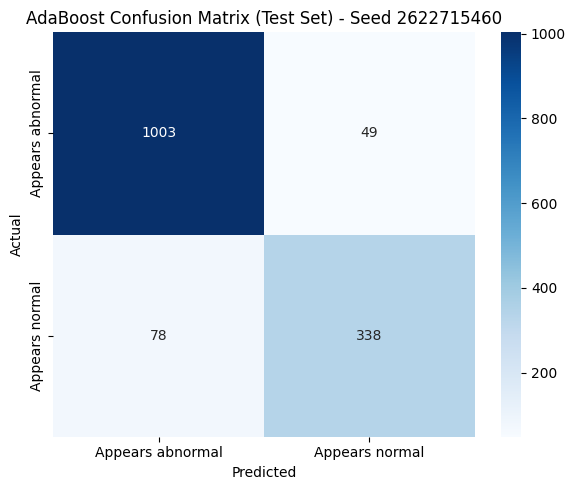


Final EfficientNet-B3 Test Loss: 0.4642 (CE: 0.4088, Dice: 0.5196), Final EfficientNet-B3 Test Accuracy: 0.9005

EfficientNet-B3 Test Precision (weighted): 0.9010
EfficientNet-B3 Test Recall (weighted): 0.9005
EfficientNet-B3 Test F1-score (weighted): 0.8969

EfficientNet-B3 Per-class report:
                  precision    recall  f1-score   support

Appears abnormal     0.8988    0.9705    0.9333      1052
  Appears normal     0.9066    0.7236    0.8048       416

        accuracy                         0.9005      1468
       macro avg     0.9027    0.8470    0.8690      1468
    weighted avg     0.9010    0.9005    0.8969      1468



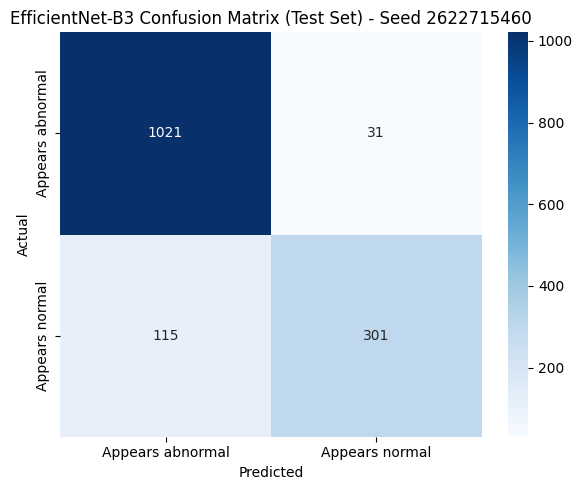

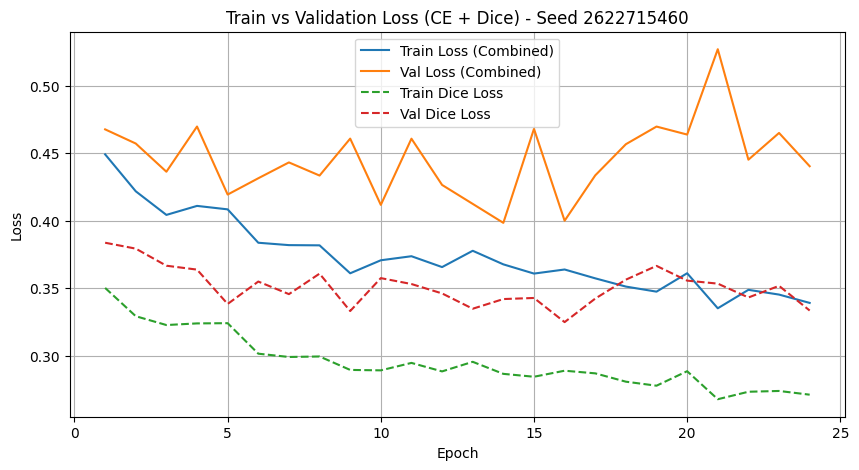

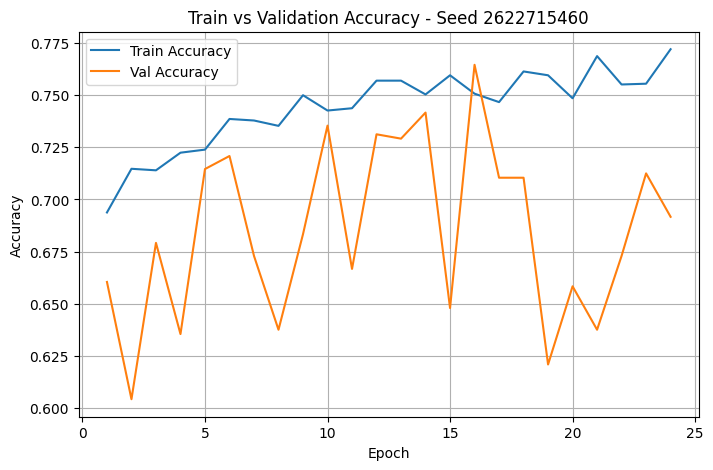


================ FINAL SUMMARY ================
Seed: 2622715460
Best EfficientNet-B3 Val Accuracy: 0.7646
EfficientNet-B3 Test Accuracy: 0.9005
EfficientNet-B3 Test Precision: 0.9010
EfficientNet-B3 Test Recall: 0.9005
EfficientNet-B3 Test F1-score: 0.8969
EfficientNet-B3 Test Dice Loss: 0.5196

---------------- AdaBoost ----------------
AdaBoost Validation Accuracy: 0.6937
AdaBoost Test Accuracy: 0.9135
AdaBoost Test Precision: 0.9124
AdaBoost Test Recall: 0.9135
AdaBoost Test F1-score: 0.9125


########## SEED = 512 ##########

Saved split indices: 2720 train / 480 val


/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=EfficientNet_B3_Weights.IMAGENET1K_V1`. You can also use `weights=EfficientNet_B3_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)
100%|██████████| 43/43 [00:41<00:00,  1.05it/s]


Epoch [1/50] Train Loss: 0.4373 (CE: 0.5317, Dice: 0.3428), Train Acc: 0.6963 | Val Loss: 0.4587 (CE: 0.5588, Dice: 0.3585), Val Acc: 0.7042
  -> Saving best model (Val Accuracy: 0.7042)


100%|██████████| 43/43 [00:38<00:00,  1.10it/s]


Epoch [2/50] Train Loss: 0.4181 (CE: 0.5091, Dice: 0.3271), Train Acc: 0.7129 | Val Loss: 0.4700 (CE: 0.5802, Dice: 0.3597), Val Acc: 0.6667
  -> No improvement for 1/8 epochs


...

Epoch [13/50] Train Loss: 0.3569 (CE: 0.4306, Dice: 0.2832), Train Acc: 0.7585 | Val Loss: 0.4431 (CE: 0.5414, Dice: 0.3449), Val Acc: 0.6917
  -> No improvement for 8/8 epochs

Early stopping triggered at epoch 13. Best Val Accuracy: 0.7562


/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=None`.
  warnings.warn(msg)


Saved model weights -> /kaggle/working/efficientnet_b3_final_weights_seed512.pth

Extracting EfficientNet-B3 features...


Extracting Features: 100%|██████████| 23/23 [00:07<00:00,  2.92it/s]



Feature shape: (2720, 1536)

Training AdaBoost...
Saved AdaBoost -> /kaggle/working/adaboost_efficientnet_b3_final_seed512.joblib

AdaBoost Validation Accuracy: 0.6917
AdaBoost Test Accuracy: 0.9271

---------------- AdaBoost Metrics ----------------
AdaBoost Test Accuracy: 0.9271
AdaBoost Test Precision (weighted): 0.9264
AdaBoost Test Recall (weighted): 0.9271
AdaBoost Test F1-score (weighted): 0.9264

AdaBoost Per-class report:
                  precision    recall  f1-score   support

Appears abnormal     0.9387    0.9610    0.9497      1052
  Appears normal     0.8951    0.8413    0.8674       416

        accuracy                         0.9271      1468
       macro avg     0.9169    0.9012    0.9086      1468
    weighted avg     0.9264    0.9271    0.9264      1468



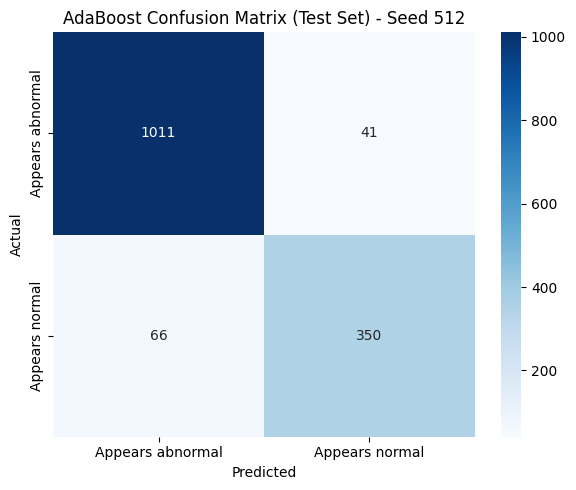


Final EfficientNet-B3 Test Loss: 0.5755 (CE: 0.6292, Dice: 0.5218), Final EfficientNet-B3 Test Accuracy: 0.8760

EfficientNet-B3 Test Precision (weighted): 0.8790
EfficientNet-B3 Test Recall (weighted): 0.8760
EfficientNet-B3 Test F1-score (weighted): 0.8685

EfficientNet-B3 Per-class report:
                  precision    recall  f1-score   support

Appears abnormal     0.8693    0.9734    0.9184      1052
  Appears normal     0.9034    0.6298    0.7422       416

        accuracy                         0.8760      1468
       macro avg     0.8864    0.8016    0.8303      1468
    weighted avg     0.8790    0.8760    0.8685      1468



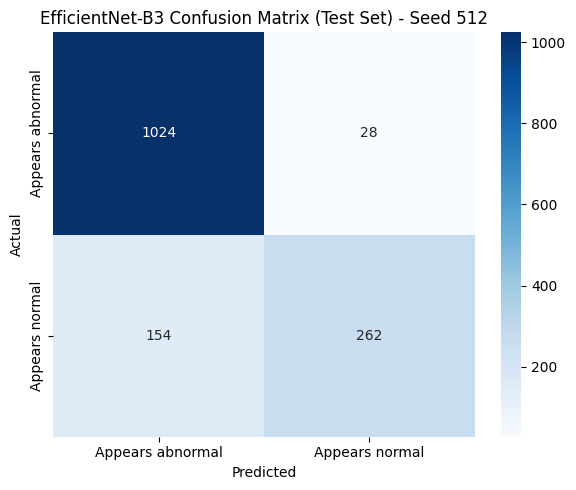

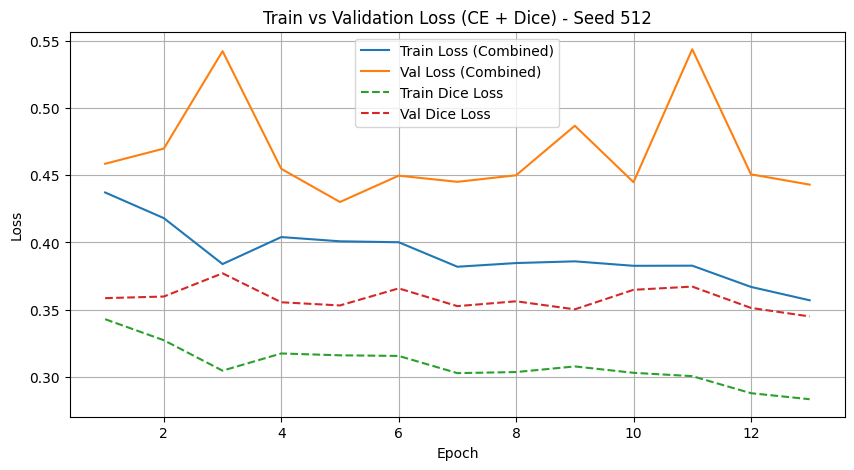

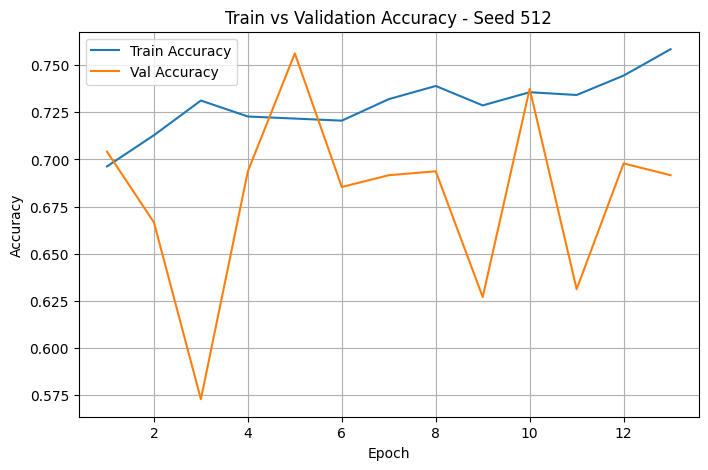


================ FINAL SUMMARY ================
Seed: 512
Best EfficientNet-B3 Val Accuracy: 0.7562
EfficientNet-B3 Test Accuracy: 0.8760
EfficientNet-B3 Test Precision: 0.8790
EfficientNet-B3 Test Recall: 0.8760
EfficientNet-B3 Test F1-score: 0.8685
EfficientNet-B3 Test Dice Loss: 0.5218

---------------- AdaBoost ----------------
AdaBoost Validation Accuracy: 0.6917
AdaBoost Test Accuracy: 0.9271
AdaBoost Test Precision: 0.9264
AdaBoost Test Recall: 0.9271
AdaBoost Test F1-score: 0.9264


########## SEED = 2 ##########

Saved split indices: 2720 train / 480 val


/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=EfficientNet_B3_Weights.IMAGENET1K_V1`. You can also use `weights=EfficientNet_B3_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)
100%|██████████| 43/43 [00:41<00:00,  1.04it/s]


Epoch [1/50] Train Loss: 0.4438 (CE: 0.5388, Dice: 0.3487), Train Acc: 0.6967 | Val Loss: 0.4609 (CE: 0.5331, Dice: 0.3887), Val Acc: 0.6062
  -> Saving best model (Val Accuracy: 0.6062)


100%|██████████| 43/43 [00:39<00:00,  1.09it/s]


Epoch [2/50] Train Loss: 0.4505 (CE: 0.5462, Dice: 0.3548), Train Acc: 0.6816 | Val Loss: 0.4497 (CE: 0.5142, Dice: 0.3852), Val Acc: 0.6813
  -> Saving best model (Val Accuracy: 0.6813)


...

Epoch [24/50] Train Loss: 0.3256 (CE: 0.3893, Dice: 0.2618), Train Acc: 0.7790 | Val Loss: 0.4715 (CE: 0.5963, Dice: 0.3466), Val Acc: 0.6708
  -> No improvement for 8/8 epochs

Early stopping triggered at epoch 24. Best Val Accuracy: 0.7250


/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=None`.
  warnings.warn(msg)


Saved model weights -> /kaggle/working/efficientnet_b3_final_weights_seed2.pth

Extracting EfficientNet-B3 features...


Extracting Features: 100%|██████████| 23/23 [00:07<00:00,  2.94it/s]



Feature shape: (2720, 1536)

Training AdaBoost...
Saved AdaBoost -> /kaggle/working/adaboost_efficientnet_b3_final_seed2.joblib

AdaBoost Validation Accuracy: 0.6833
AdaBoost Test Accuracy: 0.9108

---------------- AdaBoost Metrics ----------------
AdaBoost Test Accuracy: 0.9108
AdaBoost Test Precision (weighted): 0.9099
AdaBoost Test Recall (weighted): 0.9108
AdaBoost Test F1-score (weighted): 0.9088

AdaBoost Per-class report:
                  precision    recall  f1-score   support

Appears abnormal     0.9167    0.9629    0.9393      1052
  Appears normal     0.8926    0.7788    0.8318       416

        accuracy                         0.9108      1468
       macro avg     0.9047    0.8709    0.8856      1468
    weighted avg     0.9099    0.9108    0.9088      1468



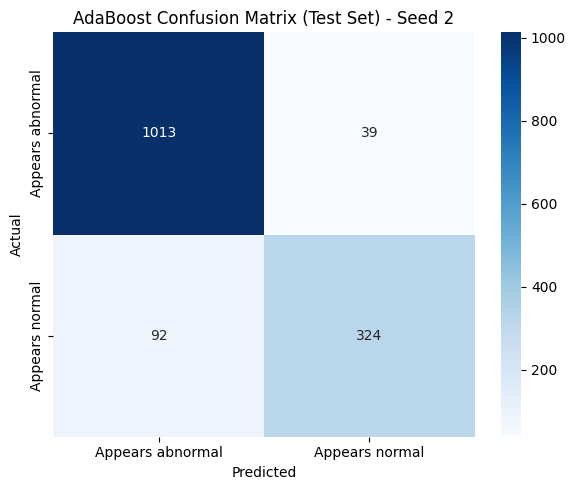


Final EfficientNet-B3 Test Loss: 0.4982 (CE: 0.4717, Dice: 0.5247), Final EfficientNet-B3 Test Accuracy: 0.8971

EfficientNet-B3 Test Precision (weighted): 0.8984
EfficientNet-B3 Test Recall (weighted): 0.8971
EfficientNet-B3 Test F1-score (weighted): 0.8927

EfficientNet-B3 Per-class report:
                  precision    recall  f1-score   support

Appears abnormal     0.8928    0.9734    0.9313      1052
  Appears normal     0.9128    0.7043    0.7951       416

        accuracy                         0.8971      1468
       macro avg     0.9028    0.8389    0.8632      1468
    weighted avg     0.8984    0.8971    0.8927      1468



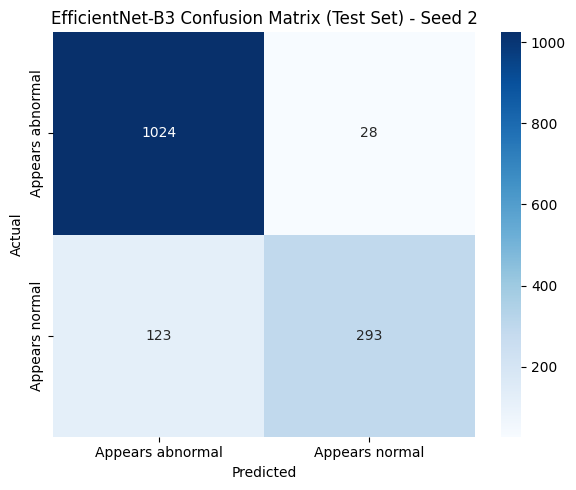

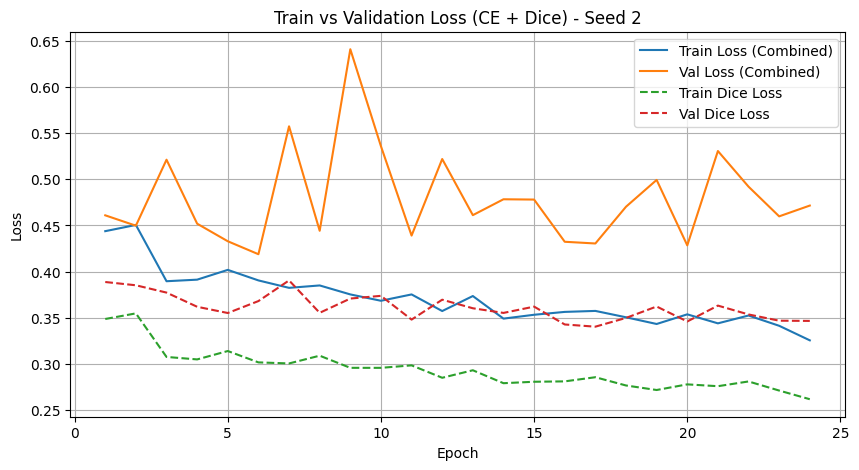

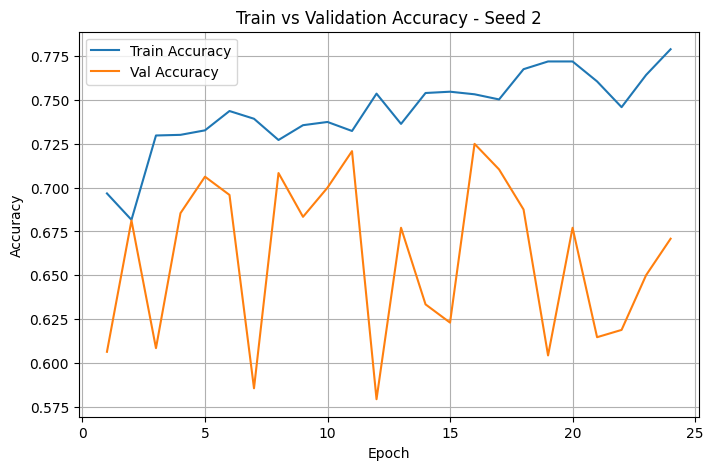


================ FINAL SUMMARY ================
Seed: 2
Best EfficientNet-B3 Val Accuracy: 0.7250
EfficientNet-B3 Test Accuracy: 0.8971
EfficientNet-B3 Test Precision: 0.8984
EfficientNet-B3 Test Recall: 0.8971
EfficientNet-B3 Test F1-score: 0.8927
EfficientNet-B3 Test Dice Loss: 0.5247

---------------- AdaBoost ----------------
AdaBoost Validation Accuracy: 0.6833
AdaBoost Test Accuracy: 0.9108
AdaBoost Test Precision: 0.9099
AdaBoost Test Recall: 0.9108
AdaBoost Test F1-score: 0.9088


=========================== PER-SEED RESULTS ===========================
Metric                             Seed 2622715460          Seed 512            Seed 2
--------------------------------------------------------------------------------------
EfficientNet-B3 Best Val Accuracy            0.7646            0.7562            0.7250
EfficientNet-B3 Test Accuracy               0.9005            0.8760            0.8971
EfficientNet-B3 Test Precision              0.9010            0.8790            0.8

In [6]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import DataLoader, WeightedRandomSampler, random_split
from torchvision import datasets, transforms, models
from tqdm import tqdm
import numpy as np
import os
import json
import joblib
import random
import gc
import matplotlib.pyplot as plt

from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

from sklearn.ensemble import AdaBoostClassifier

import seaborn as sns


# ============================================================
# Seeds for the 3-seed experiment (fixed in advance)
#   Seed 1 = same as the original single-seed run
#   Seed 2 = 512
#   Seed 3 = 2
# ============================================================
SEEDS = [2622715460, 512, 2]


# ============================================================
# Device configuration
# ============================================================
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)


# ============================================================
# Paths to train and test datasets
# ============================================================
train_dir = '/kaggle/working/PCOSGen-train/train'
test_dir = '/kaggle/working/PCOSGen-train/test'
OUT_DIR = '/kaggle/working'


# ============================================================
# Image transformations
# ============================================================
train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(20),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

test_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])


# ============================================================
# Dice Loss
# ============================================================
class DiceLoss(nn.Module):

    def __init__(self, num_classes, smooth=1e-6):
        super().__init__()
        self.num_classes = num_classes
        self.smooth = smooth

    def forward(self, logits, targets):
        probs = F.softmax(logits, dim=1)

        targets_one_hot = F.one_hot(
            targets,
            num_classes=self.num_classes
        ).float()

        intersection = (probs * targets_one_hot).sum(dim=0)

        union = probs.sum(dim=0) + targets_one_hot.sum(dim=0)

        dice_score = (2. * intersection + self.smooth) / (union + self.smooth)

        dice_loss = 1. - dice_score.mean()

        return dice_loss


# ============================================================
# Combined CrossEntropy + Dice Loss
# ============================================================
class CombinedLoss(nn.Module):

    def __init__(self, num_classes, ce_weight=0.5, dice_weight=0.5):
        super().__init__()
        self.ce_loss = nn.CrossEntropyLoss()
        self.dice_loss = DiceLoss(num_classes)
        self.ce_weight = ce_weight
        self.dice_weight = dice_weight

    def forward(self, logits, targets):
        ce = self.ce_loss(logits, targets)
        dice = self.dice_loss(logits, targets)
        total = self.ce_weight * ce + self.dice_weight * dice
        return total, ce, dice


# ============================================================
# Function to evaluate EfficientNet-B3
# ============================================================
def evaluate_model(model, loader, criterion):

    model.eval()

    correct = 0
    total = 0

    running_loss = 0.0
    running_ce = 0.0
    running_dice = 0.0

    with torch.no_grad():

        for images, labels in loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)

            loss, ce, dice = criterion(outputs, labels)

            running_loss += loss.item()
            running_ce += ce.item()
            running_dice += dice.item()

            _, predicted = torch.max(outputs, 1)

            total += labels.size(0)

            correct += (predicted == labels).sum().item()

    accuracy = correct / total

    n = len(loader)

    return (
        accuracy,
        running_loss / n,
        running_ce / n,
        running_dice / n
    )


# ============================================================
# Get predictions
# ============================================================
def get_predictions(model, loader):

    model.eval()

    all_preds = []
    all_labels = []

    with torch.no_grad():

        for images, labels in loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)

            _, predicted = torch.max(outputs, 1)

            all_preds.extend(predicted.cpu().numpy())

            all_labels.extend(labels.cpu().numpy())

    return all_labels, all_preds


# ============================================================
# Feature extraction (EfficientNet-B3 -> GAP -> flatten)
# ============================================================
def extract_features(model, loader):

    model.eval()

    features = []
    labels_list = []

    with torch.no_grad():

        for images, labels in tqdm(loader, desc="Extracting Features"):

            images = images.to(device)

            # Extract features before classifier
            x = model.features(images)

            # Global Average Pooling
            x = F.adaptive_avg_pool2d(x, (1, 1))

            # Flatten
            x = torch.flatten(x, 1)

            features.extend(x.cpu().numpy())

            labels_list.extend(labels.numpy())

    return (
        np.array(features),
        np.array(labels_list)
    )


# ============================================================
# ONE FULL EXPERIMENT FOR ONE SEED
# (identical pipeline to the original single-seed script)
# ============================================================
def run_experiment(seed):

    print(f"\n\n########## SEED = {seed} ##########\n")

    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

    # ---------------- Datasets ----------------
    train_dataset = datasets.ImageFolder(
        train_dir,
        transform=train_transform
    )

    test_dataset = datasets.ImageFolder(
        test_dir,
        transform=test_transform
    )

    # ---------------- Split train into train + val (85/15) ----------------
    val_size = int(0.15 * len(train_dataset))

    train_size = len(train_dataset) - val_size

    train_subset, val_subset = random_split(
        train_dataset,
        [train_size, val_size]
    )

    # ---------------- Save train / val indices ----------------
    split_info = {
        "seed": seed,
        "val_fraction": 0.15,
        "classes": train_dataset.classes,
        "class_to_idx": train_dataset.class_to_idx,
        "train_indices": [int(i) for i in train_subset.indices],
        "val_indices": [int(i) for i in val_subset.indices],
        "train_files": [train_dataset.samples[i][0] for i in train_subset.indices],
        "val_files": [train_dataset.samples[i][0] for i in val_subset.indices],
    }
    with open(os.path.join(OUT_DIR, f"split_indices_efficientnet_b3_seed{seed}.json"), "w") as f:
        json.dump(split_info, f)
    print(f"Saved split indices: {len(train_subset.indices)} train / {len(val_subset.indices)} val")

    # ---------------- Class weights + sampler ----------------
    train_targets = [
        train_dataset.targets[i]
        for i in train_subset.indices
    ]

    class_counts = np.bincount(
        train_targets
    )

    class_weights = 1. / class_counts

    sample_weights = [
        class_weights[label]
        for label in train_targets
    ]

    sampler = WeightedRandomSampler(
        weights=sample_weights,
        num_samples=len(train_subset),
        replacement=True
    )

    # ---------------- DataLoaders ----------------
    train_loader = DataLoader(
        train_subset,
        batch_size=64,
        sampler=sampler
    )

    val_loader = DataLoader(
        val_subset,
        batch_size=64,
        shuffle=False
    )

    test_loader = DataLoader(
        test_dataset,
        batch_size=64,
        shuffle=False
    )

    # ---------------- Load pre-trained EfficientNet-B3 ----------------
    efficientnet = models.efficientnet_b3(
        pretrained=True
    )

    num_classes = len(
        train_dataset.classes
    )

    efficientnet.classifier[1] = nn.Linear(
        efficientnet.classifier[1].in_features,
        num_classes
    )

    efficientnet = efficientnet.to(device)

    criterion = CombinedLoss(
        num_classes=num_classes,
        ce_weight=0.5,
        dice_weight=0.5
    )

    optimizer = optim.Adam(
        efficientnet.parameters(),
        lr=0.001
    )

    # ---------------- Early stopping setup ----------------
    best_accuracy = 0.0

    best_model_path = f"EfficientNetB3_best_seed{seed}.pkl"

    patience = 8

    epochs_no_improve = 0

    max_epochs = 50

    # ---------------- Lists for graphs ----------------
    train_losses = []
    train_accs = []

    val_losses = []
    val_accs = []

    train_ce_losses = []
    train_dice_losses = []

    val_ce_losses = []
    val_dice_losses = []

    # ---------------- EfficientNet-B3 Training ----------------
    for epoch in range(max_epochs):

        efficientnet.train()

        running_loss = 0.0
        running_ce = 0.0
        running_dice = 0.0

        correct_train = 0
        total_train = 0

        for images, labels in tqdm(train_loader):

            images = images.to(device)
            labels = labels.to(device)

            outputs = efficientnet(images)

            loss, ce, dice = criterion(outputs, labels)

            optimizer.zero_grad()

            loss.backward()

            optimizer.step()

            running_loss += loss.item()
            running_ce += ce.item()
            running_dice += dice.item()

            _, predicted = torch.max(outputs, 1)

            total_train += labels.size(0)

            correct_train += (predicted == labels).sum().item()

        train_accuracy = correct_train / total_train

        n_batches = len(train_loader)

        train_loss = running_loss / n_batches
        train_ce = running_ce / n_batches
        train_dice = running_dice / n_batches

        # ---------------- Validation ----------------
        val_accuracy, val_loss, val_ce, val_dice = evaluate_model(
            efficientnet,
            val_loader,
            criterion
        )

        # ---------------- Store values for graphs ----------------
        train_losses.append(train_loss)
        train_accs.append(train_accuracy)
        val_losses.append(val_loss)
        val_accs.append(val_accuracy)
        train_ce_losses.append(train_ce)
        train_dice_losses.append(train_dice)
        val_ce_losses.append(val_ce)
        val_dice_losses.append(val_dice)

        # ---------------- Print epoch results ----------------
        print(
            f'Epoch [{epoch+1}/{max_epochs}] '
            f'Train Loss: {train_loss:.4f} '
            f'(CE: {train_ce:.4f}, '
            f'Dice: {train_dice:.4f}), '
            f'Train Acc: {train_accuracy:.4f} | '
            f'Val Loss: {val_loss:.4f} '
            f'(CE: {val_ce:.4f}, '
            f'Dice: {val_dice:.4f}), '
            f'Val Acc: {val_accuracy:.4f}'
        )

        # ---------------- Early stopping logic ----------------
        if val_accuracy > best_accuracy:

            best_accuracy = val_accuracy

            epochs_no_improve = 0

            print(
                f'  -> Saving best model '
                f'(Val Accuracy: {best_accuracy:.4f})'
            )

            torch.save(efficientnet.state_dict(), best_model_path)

        else:

            epochs_no_improve += 1

            print(
                f'  -> No improvement for '
                f'{epochs_no_improve}/{patience} epochs'
            )

        if epochs_no_improve >= patience:

            print(
                f'\nEarly stopping triggered at '
                f'epoch {epoch+1}. '
                f'Best Val Accuracy: {best_accuracy:.4f}'
            )

            break

    # ---------------- Load the best EfficientNet-B3 model ----------------
    best_efficientnet_model = models.efficientnet_b3(
        pretrained=False
    )

    best_efficientnet_model.classifier[1] = nn.Linear(
        efficientnet.classifier[1].in_features,
        num_classes
    )

    best_efficientnet_model = best_efficientnet_model.to(device)

    best_efficientnet_model.load_state_dict(
        torch.load(best_model_path)
    )

    # ---------------- Save final trained EfficientNet-B3 weights ----------------
    final_weights_path = os.path.join(OUT_DIR, f"efficientnet_b3_final_weights_seed{seed}.pth")
    torch.save({
        "state_dict": best_efficientnet_model.state_dict(),
        "num_classes": num_classes,
        "classes": train_dataset.classes,
        "class_to_idx": train_dataset.class_to_idx,
        "best_val_accuracy": best_accuracy,
        "seed": seed,
        "input_size": 224,
        "normalize_mean": [0.485, 0.456, 0.406],
        "normalize_std": [0.229, 0.224, 0.225],
    }, final_weights_path)
    print("Saved model weights ->", final_weights_path)

    # ============================================================
    # ADABOOST: EfficientNet-B3 Feature Extraction + AdaBoost
    # ============================================================
    print("\nExtracting EfficientNet-B3 features...")

    train_features, train_labels = extract_features(best_efficientnet_model, train_loader)

    val_features, val_labels = extract_features(best_efficientnet_model, val_loader)

    test_features, test_labels = extract_features(best_efficientnet_model, test_loader)

    print("\nFeature shape:", train_features.shape)

    adaboost_model = AdaBoostClassifier(
        n_estimators=100,
        learning_rate=1.0,
        random_state=seed
    )

    print("\nTraining AdaBoost...")

    adaboost_model.fit(train_features, train_labels)

    adaboost_path = os.path.join(OUT_DIR, f"adaboost_efficientnet_b3_final_seed{seed}.joblib")
    joblib.dump(adaboost_model, adaboost_path)
    print("Saved AdaBoost ->", adaboost_path)

    # ---------------- AdaBoost Validation ----------------
    adaboost_val_preds = adaboost_model.predict(val_features)

    adaboost_val_accuracy = np.mean(adaboost_val_preds == val_labels)

    print(f"\nAdaBoost Validation Accuracy: {adaboost_val_accuracy:.4f}")

    # ---------------- AdaBoost Test Predictions ----------------
    adaboost_test_preds = adaboost_model.predict(test_features)

    adaboost_test_accuracy = np.mean(adaboost_test_preds == test_labels)

    print(f"AdaBoost Test Accuracy: {adaboost_test_accuracy:.4f}")

    # ---------------- AdaBoost Metrics ----------------
    class_names = train_dataset.classes

    adaboost_accuracy = np.mean(adaboost_test_preds == test_labels)

    adaboost_precision = precision_score(
        test_labels, adaboost_test_preds, average='weighted', zero_division=0
    )

    adaboost_recall = recall_score(
        test_labels, adaboost_test_preds, average='weighted', zero_division=0
    )

    adaboost_f1 = f1_score(
        test_labels, adaboost_test_preds, average='weighted', zero_division=0
    )

    print("\n---------------- AdaBoost Metrics ----------------")
    print(f"AdaBoost Test Accuracy: {adaboost_accuracy:.4f}")
    print(f"AdaBoost Test Precision (weighted): {adaboost_precision:.4f}")
    print(f"AdaBoost Test Recall (weighted): {adaboost_recall:.4f}")
    print(f"AdaBoost Test F1-score (weighted): {adaboost_f1:.4f}")

    # ---------------- AdaBoost Classification Report ----------------
    print("\nAdaBoost Per-class report:")

    print(
        classification_report(
            test_labels,
            adaboost_test_preds,
            target_names=class_names,
            digits=4,
            zero_division=0
        )
    )

    # ---------------- AdaBoost Confusion Matrix ----------------
    adaboost_cm = confusion_matrix(test_labels, adaboost_test_preds)

    plt.figure(figsize=(6, 5))

    sns.heatmap(
        adaboost_cm,
        annot=True,
        fmt='d',
        cmap='Blues',
        xticklabels=class_names,
        yticklabels=class_names
    )

    plt.xlabel('Predicted')
    plt.ylabel('Actual')
    plt.title(f'AdaBoost Confusion Matrix (Test Set) - Seed {seed}')
    plt.tight_layout()
    plt.show()

    # ---------------- EFFICIENTNET-B3 TEST EVALUATION ----------------
    test_accuracy, test_loss, test_ce, test_dice = evaluate_model(
        best_efficientnet_model,
        test_loader,
        criterion
    )

    print(
        f'\nFinal EfficientNet-B3 Test Loss: '
        f'{test_loss:.4f} '
        f'(CE: {test_ce:.4f}, '
        f'Dice: {test_dice:.4f}), '
        f'Final EfficientNet-B3 Test Accuracy: '
        f'{test_accuracy:.4f}'
    )

    # ---------------- EfficientNet-B3 Test Metrics ----------------
    true_labels, pred_labels = get_predictions(best_efficientnet_model, test_loader)

    precision = precision_score(true_labels, pred_labels, average='weighted', zero_division=0)

    recall = recall_score(true_labels, pred_labels, average='weighted', zero_division=0)

    f1 = f1_score(true_labels, pred_labels, average='weighted', zero_division=0)

    print(f'\nEfficientNet-B3 Test Precision (weighted): {precision:.4f}')
    print(f'EfficientNet-B3 Test Recall (weighted): {recall:.4f}')
    print(f'EfficientNet-B3 Test F1-score (weighted): {f1:.4f}')

    # ---------------- EfficientNet-B3 Classification Report ----------------
    print('\nEfficientNet-B3 Per-class report:')

    print(
        classification_report(
            true_labels,
            pred_labels,
            target_names=class_names,
            digits=4,
            zero_division=0
        )
    )

    # ---------------- EfficientNet-B3 Confusion Matrix ----------------
    cm = confusion_matrix(true_labels, pred_labels)

    plt.figure(figsize=(6, 5))

    sns.heatmap(
        cm,
        annot=True,
        fmt='d',
        cmap='Blues',
        xticklabels=class_names,
        yticklabels=class_names
    )

    plt.xlabel('Predicted')
    plt.ylabel('Actual')
    plt.title(f'EfficientNet-B3 Confusion Matrix (Test Set) - Seed {seed}')
    plt.tight_layout()
    plt.show()

    # ---------------- Plot Train vs Val Loss ----------------
    epochs_range = range(1, len(train_losses) + 1)

    plt.figure(figsize=(10, 5))

    plt.plot(epochs_range, train_losses, label='Train Loss (Combined)')
    plt.plot(epochs_range, val_losses, label='Val Loss (Combined)')
    plt.plot(epochs_range, train_dice_losses, '--', label='Train Dice Loss')
    plt.plot(epochs_range, val_dice_losses, '--', label='Val Dice Loss')

    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.title(f'Train vs Validation Loss (CE + Dice) - Seed {seed}')
    plt.legend()
    plt.grid(True)
    plt.show()

    # ---------------- Plot Train vs Val Accuracy ----------------
    plt.figure(figsize=(8, 5))

    plt.plot(epochs_range, train_accs, label='Train Accuracy')
    plt.plot(epochs_range, val_accs, label='Val Accuracy')

    plt.xlabel('Epoch')
    plt.ylabel('Accuracy')
    plt.title(f'Train vs Validation Accuracy - Seed {seed}')
    plt.legend()
    plt.grid(True)
    plt.show()

    # ---------------- FINAL SUMMARY (per seed) ----------------
    print('\n================ FINAL SUMMARY ================')
    print(f'Seed: {seed}')
    print(f'Best EfficientNet-B3 Val Accuracy: {best_accuracy:.4f}')
    print(f'EfficientNet-B3 Test Accuracy: {test_accuracy:.4f}')
    print(f'EfficientNet-B3 Test Precision: {precision:.4f}')
    print(f'EfficientNet-B3 Test Recall: {recall:.4f}')
    print(f'EfficientNet-B3 Test F1-score: {f1:.4f}')
    print(f'EfficientNet-B3 Test Dice Loss: {test_dice:.4f}')

    print('\n---------------- AdaBoost ----------------')
    print(f'AdaBoost Validation Accuracy: {adaboost_val_accuracy:.4f}')
    print(f'AdaBoost Test Accuracy: {adaboost_accuracy:.4f}')
    print(f'AdaBoost Test Precision: {adaboost_precision:.4f}')
    print(f'AdaBoost Test Recall: {adaboost_recall:.4f}')
    print(f'AdaBoost Test F1-score: {adaboost_f1:.4f}')

    result = {
        "seed": seed,
        "epochs_trained": len(train_losses),
        "efficientnet_best_val_acc": float(best_accuracy),
        "efficientnet_test_acc": float(test_accuracy),
        "efficientnet_test_precision": float(precision),
        "efficientnet_test_recall": float(recall),
        "efficientnet_test_f1": float(f1),
        "efficientnet_test_dice_loss": float(test_dice),
        "adaboost_val_acc": float(adaboost_val_accuracy),
        "adaboost_test_acc": float(adaboost_accuracy),
        "adaboost_test_precision": float(adaboost_precision),
        "adaboost_test_recall": float(adaboost_recall),
        "adaboost_test_f1": float(adaboost_f1),
        "efficientnet_confusion_matrix": cm.tolist(),
        "adaboost_confusion_matrix": adaboost_cm.tolist(),
    }

    # free memory before next seed
    del efficientnet, best_efficientnet_model, optimizer, train_loader, val_loader, test_loader
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    return result


# ============================================================
# RUN ALL SEEDS
# ============================================================
all_results = []

for s in SEEDS:
    all_results.append(run_experiment(s))

with open(os.path.join(OUT_DIR, "efficientnet_b3_three_seed_results.json"), "w") as f:
    json.dump(all_results, f, indent=2)


# ============================================================
# AGGREGATE: mean +/- SD over seeds
# (SD = sample standard deviation, ddof=1, n = number of seeds)
# ============================================================
METRICS = [
    ("EfficientNet-B3 Best Val Accuracy",  "efficientnet_best_val_acc"),
    ("EfficientNet-B3 Test Accuracy",      "efficientnet_test_acc"),
    ("EfficientNet-B3 Test Precision",     "efficientnet_test_precision"),
    ("EfficientNet-B3 Test Recall",        "efficientnet_test_recall"),
    ("EfficientNet-B3 Test F1-score",      "efficientnet_test_f1"),
    ("EfficientNet-B3 Test Dice Loss",     "efficientnet_test_dice_loss"),
    ("AdaBoost Validation Accuracy",   "adaboost_val_acc"),
    ("AdaBoost Test Accuracy",         "adaboost_test_acc"),
    ("AdaBoost Test Precision",        "adaboost_test_precision"),
    ("AdaBoost Test Recall",           "adaboost_test_recall"),
    ("AdaBoost Test F1-score",         "adaboost_test_f1"),
]

print('\n\n=========================== PER-SEED RESULTS ===========================')
header = f"{'Metric':<32}" + "".join(f"{('Seed ' + str(r['seed'])):>18}" for r in all_results)
print(header)
print('-' * len(header))
for name, key in METRICS:
    row = f"{name:<32}" + "".join(f"{r[key]:>18.4f}" for r in all_results)
    print(row)

print(f'\n=================== MEAN +/- SD OVER {len(all_results)} SEEDS ===================')
summary = {}
for name, key in METRICS:
    vals = np.array([r[key] for r in all_results], dtype=float)
    mean = vals.mean()
    sd = vals.std(ddof=1) if len(vals) > 1 else 0.0
    summary[key] = {"mean": float(mean), "sd": float(sd), "values": vals.tolist()}
    print(f"{name:<32}: {mean:.4f} +/- {sd:.4f}   "
          f"(min {vals.min():.4f}, max {vals.max():.4f})")

print('\nPercentage form (for the paper):')
for name, key in METRICS:
    if 'Dice' in name:
        continue
    m, s_ = summary[key]['mean'] * 100, summary[key]['sd'] * 100
    print(f"{name:<32}: {m:.2f} +/- {s_:.2f} %")

with open(os.path.join(OUT_DIR, "efficientnet_b3_three_seed_summary_mean_sd.json"), "w") as f:
    json.dump({"seeds": SEEDS, "sd_type": "sample (ddof=1)", "summary": summary}, f, indent=2)

print("\nSaved -> efficientnet_b3_three_seed_results.json, efficientnet_b3_three_seed_summary_mean_sd.json")

# Savingg

In [7]:
# ============================================================
# PACKAGE THREE-SEED EfficientNet-B3 + ADABOOST EXPERIMENT
# Run this cell AFTER the three-seed training script has finished.
# Creates ONE ZIP containing ONE folder per seed (3 folders), each with the
# split, trained models, config, environment info, dataset hashes, README.
# Does NOT retrain anything.
# ============================================================

import os
import csv
import json
import shutil
import hashlib
import platform
import zipfile
from pathlib import Path
from datetime import datetime, timezone

import torch
import torchvision
import numpy as np
import sklearn
import joblib

# ---------------- CONFIGURATION ----------------
OUT_DIR = os.environ.get("PCOS_OUT_DIR", "/kaggle/working")
TRAIN_DIR = os.path.join(OUT_DIR, "PCOSGen-train", "train")
TEST_DIR = os.path.join(OUT_DIR, "PCOSGen-train", "test")

SEEDS = [2622715460, 512, 2]

# Set True if you also want each seed's metrics JSON inside its folder.
INCLUDE_RESULTS = False

ROOT_PACKAGE_NAME = "EfficientNetB3_AdaBoost_Three_Seeds"
FOLDER_PREFIX = "EfficientNetB3_AdaBoost"
ROOT_PACKAGE_DIR = os.path.join(OUT_DIR, ROOT_PACKAGE_NAME)
ZIP_PATH = os.path.join(OUT_DIR, ROOT_PACKAGE_NAME + ".zip")
RESULTS_JSON = os.path.join(OUT_DIR, "efficientnet_b3_three_seed_results.json")


# Exact filenames written by the three-seed training script.
def seed_files(seed):
    return {
        "split": os.path.join(OUT_DIR, f"split_indices_efficientnet_b3_seed{seed}.json"),
        "weights": os.path.join(OUT_DIR, f"efficientnet_b3_final_weights_seed{seed}.pth"),
        "adaboost": os.path.join(OUT_DIR, f"adaboost_efficientnet_b3_final_seed{seed}.joblib"),
        "checkpoint": os.path.join(OUT_DIR, f"EfficientNetB3_best_seed{seed}.pkl"),
    }


def sha256_file(path):
    digest = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b""):
            digest.update(chunk)
    return digest.hexdigest()


def write_json(path, data):
    with open(path, "w", encoding="utf-8") as f:
        json.dump(data, f, indent=4)


def create_dataset_manifest(dataset_dir, output_csv):
    if not os.path.isdir(dataset_dir):
        print(f"WARNING: Dataset directory not found; manifest skipped: {dataset_dir}")
        return False
    with open(output_csv, "w", newline="", encoding="utf-8") as f:
        writer = csv.writer(f)
        writer.writerow(["relative_path", "class_name", "file_size_bytes", "sha256"])
        for path in sorted(Path(dataset_dir).rglob("*")):
            if not path.is_file():
                continue
            relative_path = path.relative_to(dataset_dir).as_posix()
            parts = Path(relative_path).parts
            class_name = parts[0] if len(parts) > 1 else ""
            writer.writerow([relative_path, class_name, path.stat().st_size, sha256_file(path)])
    return True


# ---------------- VALIDATE INPUTS ----------------
missing = []
for seed in SEEDS:
    paths = seed_files(seed)
    for key in ("split", "weights", "adaboost"):
        if not os.path.isfile(paths[key]):
            missing.append(f"Seed {seed} [{key}]: {paths[key]}")

if missing:
    raise FileNotFoundError(
        "Cannot package all three seeds. Required files are missing:\n- "
        + "\n- ".join(missing)
        + "\nRun the three-seed training script (the version that SAVES split, "
          "weights and AdaBoost) and confirm these files exist."
    )

# ---------------- CLEAN PACKAGE DIRECTORY ----------------
if os.path.exists(ROOT_PACKAGE_DIR):
    shutil.rmtree(ROOT_PACKAGE_DIR)
os.makedirs(ROOT_PACKAGE_DIR, exist_ok=True)

# ---------------- SHARED ENVIRONMENT METADATA ----------------
environment = {
    "created_utc": datetime.now(timezone.utc).isoformat(),
    "python_version": platform.python_version(),
    "platform": platform.platform(),
    "pytorch_version": str(torch.__version__),
    "torchvision_version": str(torchvision.__version__),
    "numpy_version": np.__version__,
    "scikit_learn_version": sklearn.__version__,
    "joblib_version": joblib.__version__,
    "cuda_available": torch.cuda.is_available(),
    "cuda_version": torch.version.cuda,
    "gpu_name": torch.cuda.get_device_name(0) if torch.cuda.is_available() else None,
}

# ---------------- DATASET MANIFESTS (hashed ONCE, copied into each seed) ----------------
manifest_tmp = os.path.join(OUT_DIR, "_manifest_tmp_" + ROOT_PACKAGE_NAME)
if os.path.exists(manifest_tmp):
    shutil.rmtree(manifest_tmp)
os.makedirs(manifest_tmp, exist_ok=True)
print("Hashing dataset files (done once)...")
create_dataset_manifest(TRAIN_DIR, os.path.join(manifest_tmp, "train_dataset_manifest.csv"))
create_dataset_manifest(TEST_DIR, os.path.join(manifest_tmp, "test_dataset_manifest.csv"))

all_results = None
if INCLUDE_RESULTS and os.path.isfile(RESULTS_JSON):
    with open(RESULTS_JSON, "r", encoding="utf-8") as f:
        all_results = json.load(f)

# ---------------- BUILD EACH SEED FOLDER ----------------
for seed in SEEDS:
    paths = seed_files(seed)
    folder_name = f"{FOLDER_PREFIX}_Seed_{seed}"
    package_dir = os.path.join(ROOT_PACKAGE_DIR, folder_name)

    for subfolder in ("splits", "models", "config", "metadata"):
        os.makedirs(os.path.join(package_dir, subfolder), exist_ok=True)

    # ----- split: read + validate -----
    with open(paths["split"], "r", encoding="utf-8") as f:
        split_info = json.load(f)

    if int(split_info.get("seed", -1)) != seed:
        raise ValueError(
            f"Seed mismatch in {paths['split']}: found {split_info.get('seed')}, expected {seed}"
        )
    for split_name in ("train", "val"):
        if len(split_info.get(f"{split_name}_indices", [])) != len(
            split_info.get(f"{split_name}_files", [])
        ):
            raise ValueError(f"Seed {seed}: {split_name} index/file count mismatch.")
    if set(split_info["train_indices"]) & set(split_info["val_indices"]):
        raise ValueError(f"Seed {seed}: train/validation indices overlap.")

    shutil.copy2(paths["split"], os.path.join(package_dir, "splits", "split_indices.json"))
    with open(os.path.join(package_dir, "splits", "split_images.csv"),
              "w", newline="", encoding="utf-8") as f:
        writer = csv.writer(f)
        writer.writerow(["split", "dataset_index", "image_name", "image_path", "class_name"])
        for split_name in ("train", "val"):
            for index, image_path in zip(
                split_info[f"{split_name}_indices"], split_info[f"{split_name}_files"]
            ):
                writer.writerow([
                    split_name, index, os.path.basename(image_path), image_path,
                    os.path.basename(os.path.dirname(image_path)),
                ])

    # ----- models -----
    weights_name = os.path.basename(paths["weights"])
    adaboost_name = os.path.basename(paths["adaboost"])
    shutil.copy2(paths["weights"], os.path.join(package_dir, "models", weights_name))
    shutil.copy2(paths["adaboost"], os.path.join(package_dir, "models", adaboost_name))

    checkpoint_name = None
    if os.path.isfile(paths["checkpoint"]):
        checkpoint_name = os.path.basename(paths["checkpoint"])
        shutil.copy2(paths["checkpoint"], os.path.join(package_dir, "models", checkpoint_name))

    # ----- config (read from the saved files, nothing hard-coded that could be wrong) -----
    checkpoint = torch.load(paths["weights"], map_location="cpu", weights_only=False)
    adaboost_model = joblib.load(paths["adaboost"])

    config = {
        "project": "PCOS ultrasound image classification",
        "architecture": "EfficientNet-B3 feature extractor + AdaBoost",
        "seed": seed,
        "dataset_split": {
            "method": "random_split",
            "validation_fraction": split_info.get("val_fraction", 0.15),
            "train_count": len(split_info["train_indices"]),
            "validation_count": len(split_info["val_indices"]),
            "indices_file": "splits/split_indices.json",
            "image_manifest": "splits/split_images.csv",
        },
        "classes": split_info["classes"],
        "class_to_idx": split_info["class_to_idx"],
        "cnn": {
            "name": "EfficientNet-B3",
            "weights_file": f"models/{weights_name}",
            "best_checkpoint_file": f"models/{checkpoint_name}" if checkpoint_name else None,
            "num_classes": checkpoint["num_classes"],
            "best_validation_accuracy": checkpoint["best_val_accuracy"],
            "input_size": checkpoint["input_size"],
            "normalization_mean": checkpoint["normalize_mean"],
            "normalization_std": checkpoint["normalize_std"],
            "optimizer": "Adam",
            "learning_rate": 0.001,
            "batch_size": 64,
            "max_epochs": 50,
            "early_stopping_patience": 8,
            "loss": "0.5 * CrossEntropyLoss + 0.5 * DiceLoss",
            "sampler": "WeightedRandomSampler (inverse class frequency)",
            "training_augmentations": [
                "Resize(224, 224)", "RandomHorizontalFlip", "RandomRotation(20)"
            ],
            "feature_extraction": "model.features -> global average pooling -> flatten",
        },
        "adaboost": {
            "model_file": f"models/{adaboost_name}",
            "n_estimators": getattr(adaboost_model, "n_estimators", None),
            "learning_rate": getattr(adaboost_model, "learning_rate", None),
            "random_state": getattr(adaboost_model, "random_state", None),
        },
        "original_kaggle_paths": {"train": TRAIN_DIR, "test": TEST_DIR},
        "note": (
            "Paths refer to the original Kaggle environment. Restore the saved split, "
            "preserve ImageFolder class ordering and preprocessing."
        ),
    }
    write_json(os.path.join(package_dir, "config", "model_config.json"), config)

    seed_environment = dict(environment)
    seed_environment["seed"] = int(seed)
    write_json(os.path.join(package_dir, "metadata", "environment.json"), seed_environment)

    for manifest_name in ("train_dataset_manifest.csv", "test_dataset_manifest.csv"):
        src = os.path.join(manifest_tmp, manifest_name)
        if os.path.isfile(src):
            shutil.copy2(src, os.path.join(package_dir, "metadata", manifest_name))

    # ----- optional per-seed results -----
    if all_results is not None:
        seed_result = next((r for r in all_results if int(r.get("seed", -1)) == seed), None)
        if seed_result is not None:
            os.makedirs(os.path.join(package_dir, "results"), exist_ok=True)
            write_json(os.path.join(package_dir, "results", "seed_results.json"), seed_result)

    # ----- hashes of everything in this seed folder (except the hash file itself) -----
    hashes = {}
    for file_path in sorted(Path(package_dir).rglob("*")):
        if file_path.is_file():
            hashes[file_path.relative_to(package_dir).as_posix()] = sha256_file(file_path)
    write_json(os.path.join(package_dir, "metadata", "artifact_sha256.json"), hashes)

    readme = f"""{folder_name}
{'=' * len(folder_name)}

CONTENTS
--------
splits/split_indices.json
    Exact train/validation indices, image paths, seed and class mapping.
splits/split_images.csv
    Train/validation image manifest with class names.
models/{weights_name}
    Final trained EfficientNet-B3 weights + inference settings.
models/{adaboost_name}
    Trained AdaBoost classifier (on EfficientNet-B3 features).
models/{checkpoint_name or '(best checkpoint not found)'}
    Best-validation training checkpoint.
config/model_config.json
    Architecture, preprocessing and training configuration.
metadata/environment.json
    Python, library, platform and CUDA information.
metadata/train_dataset_manifest.csv, metadata/test_dataset_manifest.csv
    Dataset file paths, sizes and SHA-256 hashes.
metadata/artifact_sha256.json
    SHA-256 hashes of every file in this seed folder.

REPRODUCTION NOTES
------------------
1. Use the same dataset version, image files and labels (verify with the manifests).
2. Restore the saved train/validation split; do not create a new split.
3. Preserve ImageFolder class ordering and preprocessing.
4. Load the saved models for inference, or re-run the training notebook with this seed.
5. A matching seed alone does not guarantee bit-identical results across hardware
   or software versions.

IMPORTANT
---------
The dataset images and the training notebook are not included.
Absolute paths refer to the original Kaggle environment.
Metrics/result files are {'included' if all_results is not None else 'NOT included'} in this package.
"""
    with open(os.path.join(package_dir, "README.txt"), "w", encoding="utf-8") as f:
        f.write(readme.strip() + "\n")

    print(
        f"Prepared seed {seed}: {len(split_info['train_indices'])} train / "
        f"{len(split_info['val_indices'])} validation images"
    )

shutil.rmtree(manifest_tmp, ignore_errors=True)

# ---------------- ROOT README ----------------
root_readme = f"""EfficientNet-B3 + AdaBoost: Three-Seed Reproducibility Package

One folder per seed:
""" + "\n".join(f"- {FOLDER_PREFIX}_Seed_{s}" for s in SEEDS) + """

Each folder holds that seed's split, trained models, configuration,
environment metadata, dataset hashes, artifact hashes and a README.
The dataset images and the training notebook are not included.
"""
with open(os.path.join(ROOT_PACKAGE_DIR, "README.txt"), "w", encoding="utf-8") as f:
    f.write(root_readme)

# ---------------- CREATE ZIP ----------------
if os.path.exists(ZIP_PATH):
    os.remove(ZIP_PATH)

with zipfile.ZipFile(ZIP_PATH, "w", compression=zipfile.ZIP_DEFLATED) as archive:
    for path in sorted(Path(ROOT_PACKAGE_DIR).rglob("*")):
        if path.is_file():
            archive.write(path, arcname=path.relative_to(OUT_DIR).as_posix())

# ---------------- VERIFY ZIP ----------------
with zipfile.ZipFile(ZIP_PATH, "r") as archive:
    bad_file = archive.testzip()
    if bad_file is not None:
        raise RuntimeError(f"ZIP verification failed: {bad_file}")
    names = archive.namelist()

for seed in SEEDS:
    prefix = f"{ROOT_PACKAGE_NAME}/{FOLDER_PREFIX}_Seed_{seed}/"
    if not any(n.startswith(prefix) for n in names):
        raise RuntimeError(f"Seed folder missing from ZIP: {prefix}")

print("\nZIP CREATED AND VERIFIED SUCCESSFULLY")
print("File:", ZIP_PATH)
print("Size: {:.2f} MB".format(os.path.getsize(ZIP_PATH) / (1024 ** 2)))
print("\nZIP CONTENTS:")
for n in names:
    print(" -", n)

Hashing dataset files (done once)...
Prepared seed 2622715460: 2720 train / 480 validation images
Prepared seed 512: 2720 train / 480 validation images
Prepared seed 2: 2720 train / 480 validation images

ZIP CREATED AND VERIFIED SUCCESSFULLY
File: /kaggle/working/EfficientNetB3_AdaBoost_Three_Seeds.zip
Size: 230.39 MB

ZIP CONTENTS:
 - EfficientNetB3_AdaBoost_Three_Seeds/EfficientNetB3_AdaBoost_Seed_2/README.txt
 - EfficientNetB3_AdaBoost_Three_Seeds/EfficientNetB3_AdaBoost_Seed_2/config/model_config.json
 - EfficientNetB3_AdaBoost_Three_Seeds/EfficientNetB3_AdaBoost_Seed_2/metadata/artifact_sha256.json
 - EfficientNetB3_AdaBoost_Three_Seeds/EfficientNetB3_AdaBoost_Seed_2/metadata/environment.json
 - EfficientNetB3_AdaBoost_Three_Seeds/EfficientNetB3_AdaBoost_Seed_2/metadata/test_dataset_manifest.csv
 - EfficientNetB3_AdaBoost_Three_Seeds/EfficientNetB3_AdaBoost_Seed_2/metadata/train_dataset_manifest.csv
 - EfficientNetB3_AdaBoost_Three_Seeds/EfficientNetB3_AdaBoost_Seed_2/models/Effi

# EfficientNet B0 with Adaboost



########## SEED = 2622715460 ##########

Saved split indices: 2720 train / 480 val
Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=EfficientNet_B0_Weights.IMAGENET1K_V1`. You can also use `weights=EfficientNet_B0_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)
100%|██████████| 20.5M/20.5M [00:00<00:00, 148MB/s] 
100%|██████████| 43/43 [00:23<00:00,  1.87it/s]


Epoch [1/50] Train Loss: 0.4589 (CE: 0.5554, Dice: 0.3623), Train Acc: 0.6695 | Val Loss: 0.4537 (CE: 0.5277, Dice: 0.3797), Val Acc: 0.6771
  -> Saving best model (Val Accuracy: 0.6771)


100%|██████████| 43/43 [00:23<00:00,  1.85it/s]


Epoch [2/50] Train Loss: 0.4439 (CE: 0.5364, Dice: 0.3514), Train Acc: 0.6853 | Val Loss: 0.4273 (CE: 0.4996, Dice: 0.3549), Val Acc: 0.7042
  -> Saving best model (Val Accuracy: 0.7042)


...

Epoch [10/50] Train Loss: 0.3996 (CE: 0.4861, Dice: 0.3131), Train Acc: 0.7243 | Val Loss: 0.4280 (CE: 0.4912, Dice: 0.3647), Val Acc: 0.6479
  -> No improvement for 8/8 epochs

Early stopping triggered at epoch 10. Best Val Accuracy: 0.7042


/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=None`.
  warnings.warn(msg)


Saved model weights -> /kaggle/working/efficientnet_b0_final_weights_seed2622715460.pth

Extracting EfficientNet-B0 features...


Extracting Features: 100%|██████████| 23/23 [00:05<00:00,  4.05it/s]



Feature shape: (2720, 1280)

Training AdaBoost...
Saved AdaBoost -> /kaggle/working/adaboost_efficientnet_final_seed2622715460.joblib

AdaBoost Validation Accuracy: 0.7146
AdaBoost Test Accuracy: 0.9264

---------------- AdaBoost Metrics ----------------
AdaBoost Test Accuracy: 0.9264
AdaBoost Test Precision (weighted): 0.9262
AdaBoost Test Recall (weighted): 0.9264
AdaBoost Test F1-score (weighted): 0.9249

AdaBoost Per-class report:
                  precision    recall  f1-score   support

Appears abnormal     0.9283    0.9724    0.9499      1052
  Appears normal     0.9208    0.8101    0.8619       416

        accuracy                         0.9264      1468
       macro avg     0.9245    0.8913    0.9059      1468
    weighted avg     0.9262    0.9264    0.9249      1468



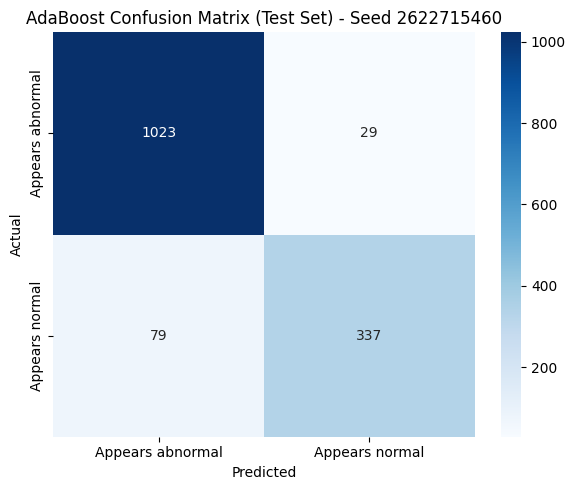


Final EfficientNet-B0 Test Loss: 0.4504 (CE: 0.3816, Dice: 0.5193), Final EfficientNet-B0 Test Accuracy: 0.8903

EfficientNet-B0 Test Precision (weighted): 0.8891
EfficientNet-B0 Test Recall (weighted): 0.8903
EfficientNet-B0 Test F1-score (weighted): 0.8869

EfficientNet-B0 Per-class report:
                  precision    recall  f1-score   support

Appears abnormal     0.8960    0.9582    0.9260      1052
  Appears normal     0.8717    0.7188    0.7879       416

        accuracy                         0.8903      1468
       macro avg     0.8839    0.8385    0.8570      1468
    weighted avg     0.8891    0.8903    0.8869      1468



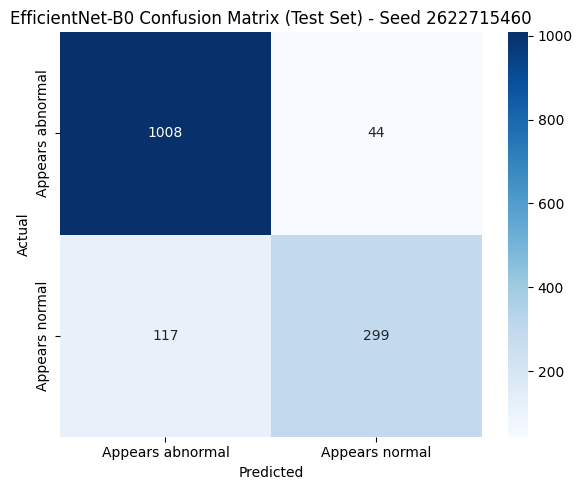

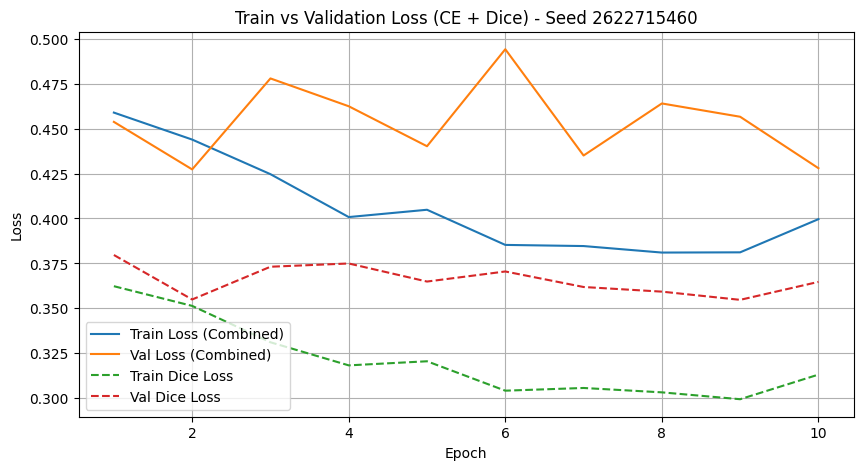

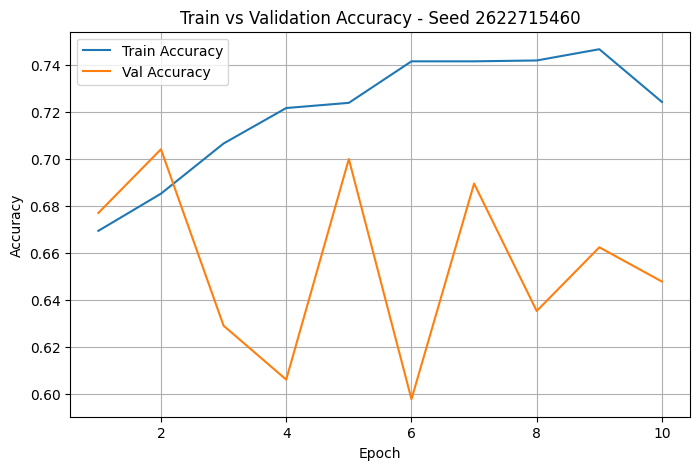


================ FINAL SUMMARY ================
Seed: 2622715460
Best EfficientNet-B0 Val Accuracy: 0.7042
EfficientNet-B0 Test Accuracy: 0.8903
EfficientNet-B0 Test Precision: 0.8891
EfficientNet-B0 Test Recall: 0.8903
EfficientNet-B0 Test F1-score: 0.8869
EfficientNet-B0 Test Dice Loss: 0.5193

---------------- AdaBoost ----------------
AdaBoost Validation Accuracy: 0.7146
AdaBoost Test Accuracy: 0.9264
AdaBoost Test Precision: 0.9262
AdaBoost Test Recall: 0.9264
AdaBoost Test F1-score: 0.9249


/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=EfficientNet_B0_Weights.IMAGENET1K_V1`. You can also use `weights=EfficientNet_B0_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)




########## SEED = 512 ##########

Saved split indices: 2720 train / 480 val


100%|██████████| 43/43 [00:22<00:00,  1.88it/s]


Epoch [1/50] Train Loss: 0.4553 (CE: 0.5491, Dice: 0.3615), Train Acc: 0.6732 | Val Loss: 0.4833 (CE: 0.5889, Dice: 0.3776), Val Acc: 0.5729
  -> Saving best model (Val Accuracy: 0.5729)


...

Epoch [30/50] Train Loss: 0.3351 (CE: 0.4021, Dice: 0.2681), Train Acc: 0.7691 | Val Loss: 0.4825 (CE: 0.6290, Dice: 0.3359), Val Acc: 0.6896
  -> No improvement for 8/8 epochs

Early stopping triggered at epoch 30. Best Val Accuracy: 0.7562


/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=None`.
  warnings.warn(msg)


Saved model weights -> /kaggle/working/efficientnet_b0_final_weights_seed512.pth

Extracting EfficientNet-B0 features...


Extracting Features: 100%|██████████| 23/23 [00:05<00:00,  3.98it/s]



Feature shape: (2720, 1280)

Training AdaBoost...
Saved AdaBoost -> /kaggle/working/adaboost_efficientnet_final_seed512.joblib

AdaBoost Validation Accuracy: 0.6750
AdaBoost Test Accuracy: 0.9183

---------------- AdaBoost Metrics ----------------
AdaBoost Test Accuracy: 0.9183
AdaBoost Test Precision (weighted): 0.9173
AdaBoost Test Recall (weighted): 0.9183
AdaBoost Test F1-score (weighted): 0.9172

AdaBoost Per-class report:
                  precision    recall  f1-score   support

Appears abnormal     0.9291    0.9591    0.9439      1052
  Appears normal     0.8874    0.8149    0.8496       416

        accuracy                         0.9183      1468
       macro avg     0.9083    0.8870    0.8967      1468
    weighted avg     0.9173    0.9183    0.9172      1468



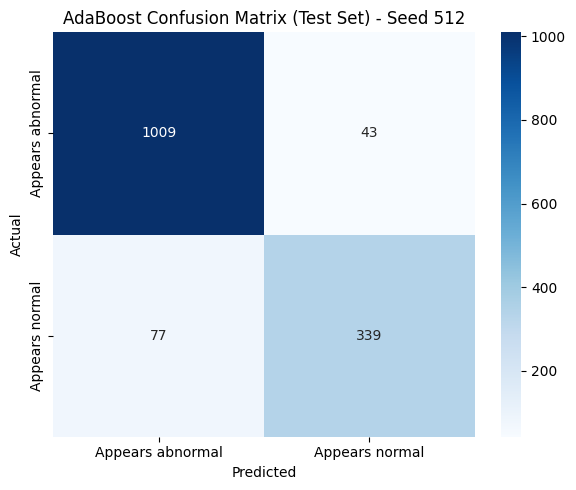


Final EfficientNet-B0 Test Loss: 0.4755 (CE: 0.4292, Dice: 0.5218), Final EfficientNet-B0 Test Accuracy: 0.8958

EfficientNet-B0 Test Precision (weighted): 0.8952
EfficientNet-B0 Test Recall (weighted): 0.8958
EfficientNet-B0 Test F1-score (weighted): 0.8923

EfficientNet-B0 Per-class report:
                  precision    recall  f1-score   support

Appears abnormal     0.8981    0.9639    0.9298      1052
  Appears normal     0.8879    0.7236    0.7974       416

        accuracy                         0.8958      1468
       macro avg     0.8930    0.8437    0.8636      1468
    weighted avg     0.8952    0.8958    0.8923      1468



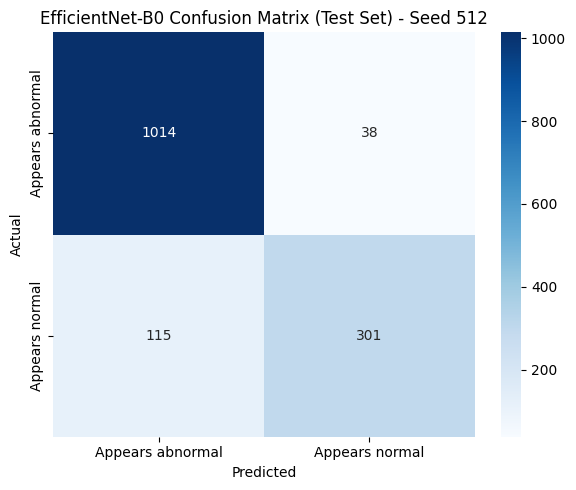

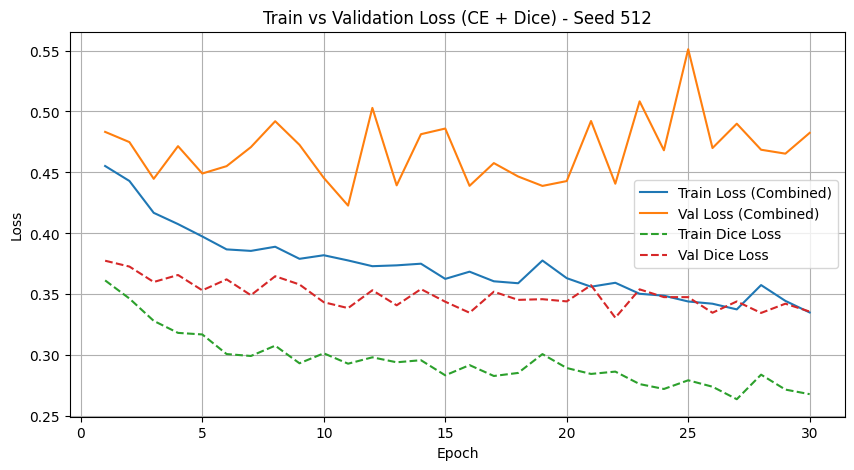

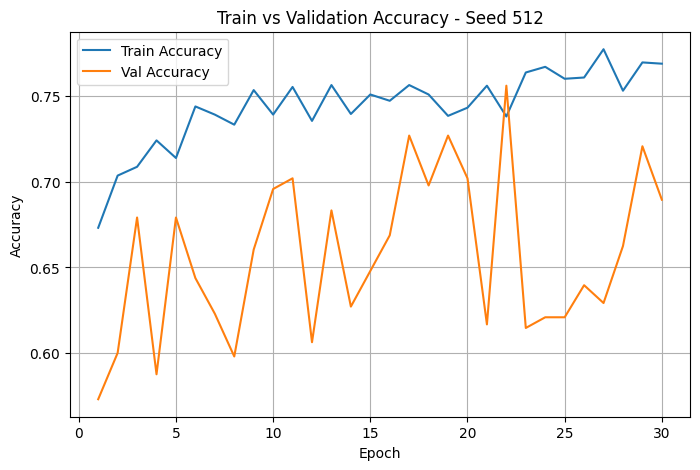


================ FINAL SUMMARY ================
Seed: 512
Best EfficientNet-B0 Val Accuracy: 0.7562
EfficientNet-B0 Test Accuracy: 0.8958
EfficientNet-B0 Test Precision: 0.8952
EfficientNet-B0 Test Recall: 0.8958
EfficientNet-B0 Test F1-score: 0.8923
EfficientNet-B0 Test Dice Loss: 0.5218

---------------- AdaBoost ----------------
AdaBoost Validation Accuracy: 0.6750
AdaBoost Test Accuracy: 0.9183
AdaBoost Test Precision: 0.9173
AdaBoost Test Recall: 0.9183
AdaBoost Test F1-score: 0.9172


/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=EfficientNet_B0_Weights.IMAGENET1K_V1`. You can also use `weights=EfficientNet_B0_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)




########## SEED = 2 ##########

Saved split indices: 2720 train / 480 val


100%|██████████| 43/43 [00:23<00:00,  1.86it/s]


Epoch [1/50] Train Loss: 0.4650 (CE: 0.5678, Dice: 0.3622), Train Acc: 0.6813 | Val Loss: 0.4970 (CE: 0.6003, Dice: 0.3938), Val Acc: 0.5542
  -> Saving best model (Val Accuracy: 0.5542)


...

Epoch [17/50] Train Loss: 0.3660 (CE: 0.4458, Dice: 0.2861), Train Acc: 0.7574 | Val Loss: 0.4978 (CE: 0.6331, Dice: 0.3626), Val Acc: 0.6021
  -> No improvement for 8/8 epochs

Early stopping triggered at epoch 17. Best Val Accuracy: 0.7562


/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=None`.
  warnings.warn(msg)


Saved model weights -> /kaggle/working/efficientnet_b0_final_weights_seed2.pth

Extracting EfficientNet-B0 features...


Extracting Features: 100%|██████████| 23/23 [00:05<00:00,  4.06it/s]



Feature shape: (2720, 1280)

Training AdaBoost...
Saved AdaBoost -> /kaggle/working/adaboost_efficientnet_final_seed2.joblib

AdaBoost Validation Accuracy: 0.6000
AdaBoost Test Accuracy: 0.9176

---------------- AdaBoost Metrics ----------------
AdaBoost Test Accuracy: 0.9176
AdaBoost Test Precision (weighted): 0.9179
AdaBoost Test Recall (weighted): 0.9176
AdaBoost Test F1-score (weighted): 0.9177

AdaBoost Per-class report:
                  precision    recall  f1-score   support

Appears abnormal     0.9446    0.9401    0.9424      1052
  Appears normal     0.8504    0.8606    0.8554       416

        accuracy                         0.9176      1468
       macro avg     0.8975    0.9003    0.8989      1468
    weighted avg     0.9179    0.9176    0.9177      1468



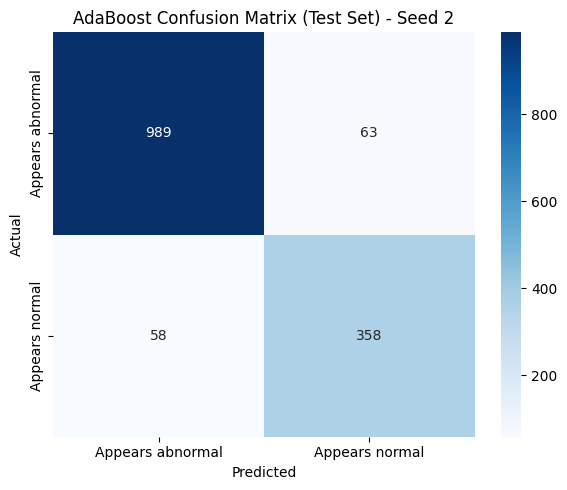


Final EfficientNet-B0 Test Loss: 0.4456 (CE: 0.3668, Dice: 0.5244), Final EfficientNet-B0 Test Accuracy: 0.8842

EfficientNet-B0 Test Precision (weighted): 0.8868
EfficientNet-B0 Test Recall (weighted): 0.8842
EfficientNet-B0 Test F1-score (weighted): 0.8778

EfficientNet-B0 Per-class report:
                  precision    recall  f1-score   support

Appears abnormal     0.8776    0.9743    0.9234      1052
  Appears normal     0.9100    0.6562    0.7626       416

        accuracy                         0.8842      1468
       macro avg     0.8938    0.8153    0.8430      1468
    weighted avg     0.8868    0.8842    0.8778      1468



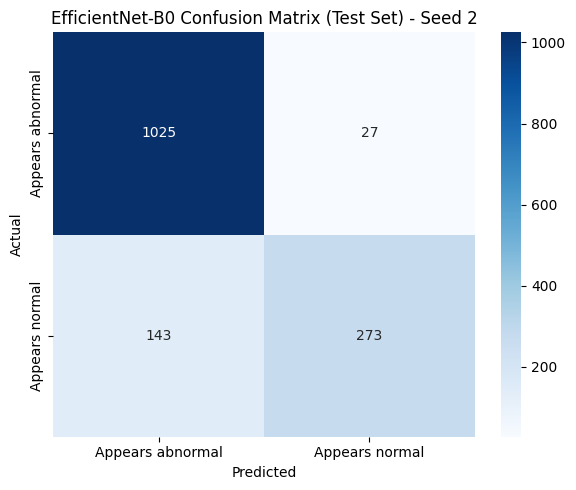

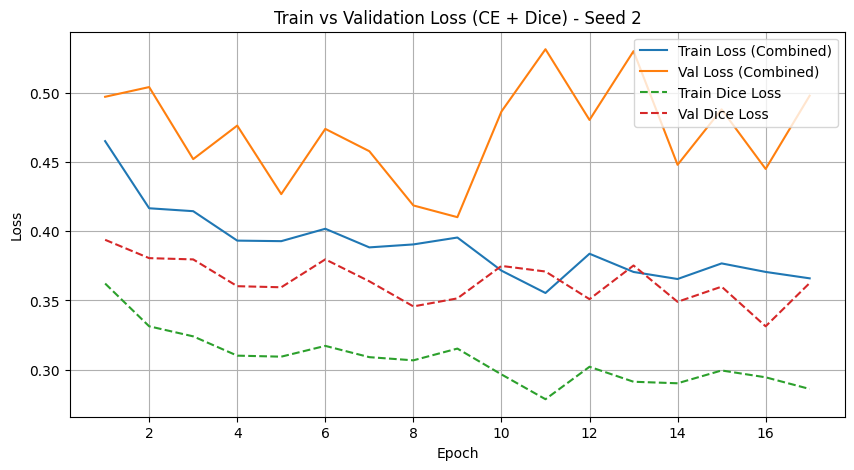

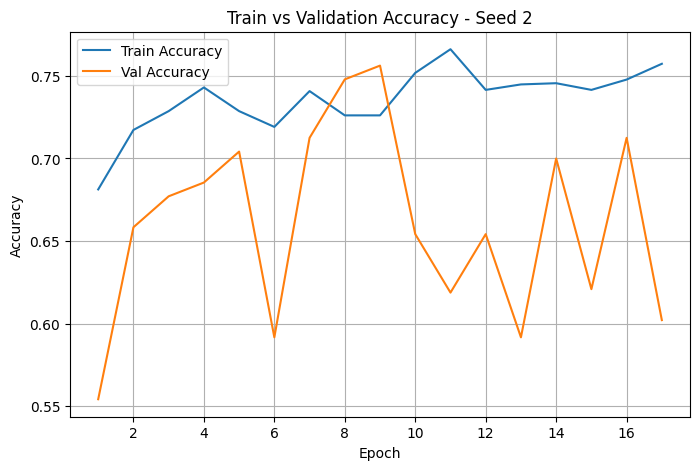


================ FINAL SUMMARY ================
Seed: 2
Best EfficientNet-B0 Val Accuracy: 0.7562
EfficientNet-B0 Test Accuracy: 0.8842
EfficientNet-B0 Test Precision: 0.8868
EfficientNet-B0 Test Recall: 0.8842
EfficientNet-B0 Test F1-score: 0.8778
EfficientNet-B0 Test Dice Loss: 0.5244

---------------- AdaBoost ----------------
AdaBoost Validation Accuracy: 0.6000
AdaBoost Test Accuracy: 0.9176
AdaBoost Test Precision: 0.9179
AdaBoost Test Recall: 0.9176
AdaBoost Test F1-score: 0.9177


=========================== PER-SEED RESULTS ===========================
Metric                             Seed 2622715460          Seed 512            Seed 2
--------------------------------------------------------------------------------------
EfficientNet-B0 Best Val Accuracy            0.7042            0.7562            0.7562
EfficientNet-B0 Test Accuracy               0.8903            0.8958            0.8842
EfficientNet-B0 Test Precision              0.8891            0.8952            0.8

In [8]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import DataLoader, WeightedRandomSampler, random_split
from torchvision import datasets, transforms, models
from tqdm import tqdm
import numpy as np
import os
import json
import joblib
import random
import gc
import matplotlib.pyplot as plt

from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

from sklearn.ensemble import AdaBoostClassifier

import seaborn as sns


# ============================================================
# Seeds for the 3-seed experiment (fixed in advance)
#   Seed 1 = same as the original single-seed run
#   Seed 2 = 512
#   Seed 3 = 2
# ============================================================
SEEDS = [2622715460, 512, 2]


# ============================================================
# Device configuration
# ============================================================
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)


# ============================================================
# Paths to train and test datasets
# ============================================================
train_dir = '/kaggle/working/PCOSGen-train/train'
test_dir = '/kaggle/working/PCOSGen-train/test'
OUT_DIR = '/kaggle/working'


# ============================================================
# Image transformations
# ============================================================
train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(20),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

test_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])


# ============================================================
# Dice Loss
# ============================================================
class DiceLoss(nn.Module):

    def __init__(self, num_classes, smooth=1e-6):
        super().__init__()
        self.num_classes = num_classes
        self.smooth = smooth

    def forward(self, logits, targets):
        probs = F.softmax(logits, dim=1)

        targets_one_hot = F.one_hot(
            targets,
            num_classes=self.num_classes
        ).float()

        intersection = (probs * targets_one_hot).sum(dim=0)

        union = probs.sum(dim=0) + targets_one_hot.sum(dim=0)

        dice_score = (2. * intersection + self.smooth) / (union + self.smooth)

        dice_loss = 1. - dice_score.mean()

        return dice_loss


# ============================================================
# Combined CrossEntropy + Dice Loss
# ============================================================
class CombinedLoss(nn.Module):

    def __init__(self, num_classes, ce_weight=0.5, dice_weight=0.5):
        super().__init__()
        self.ce_loss = nn.CrossEntropyLoss()
        self.dice_loss = DiceLoss(num_classes)
        self.ce_weight = ce_weight
        self.dice_weight = dice_weight

    def forward(self, logits, targets):
        ce = self.ce_loss(logits, targets)
        dice = self.dice_loss(logits, targets)
        total = self.ce_weight * ce + self.dice_weight * dice
        return total, ce, dice


# ============================================================
# Function to evaluate EfficientNet-B0
# ============================================================
def evaluate_model(model, loader, criterion):

    model.eval()

    correct = 0
    total = 0

    running_loss = 0.0
    running_ce = 0.0
    running_dice = 0.0

    with torch.no_grad():

        for images, labels in loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)

            loss, ce, dice = criterion(outputs, labels)

            running_loss += loss.item()
            running_ce += ce.item()
            running_dice += dice.item()

            _, predicted = torch.max(outputs, 1)

            total += labels.size(0)

            correct += (predicted == labels).sum().item()

    accuracy = correct / total

    n = len(loader)

    return (
        accuracy,
        running_loss / n,
        running_ce / n,
        running_dice / n
    )


# ============================================================
# Get predictions
# ============================================================
def get_predictions(model, loader):

    model.eval()

    all_preds = []
    all_labels = []

    with torch.no_grad():

        for images, labels in loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)

            _, predicted = torch.max(outputs, 1)

            all_preds.extend(predicted.cpu().numpy())

            all_labels.extend(labels.cpu().numpy())

    return all_labels, all_preds


# ============================================================
# Feature extraction (EfficientNet-B0 -> GAP -> flatten)
# ============================================================
def extract_features(model, loader):

    model.eval()

    features = []
    labels_list = []

    with torch.no_grad():

        for images, labels in tqdm(loader, desc="Extracting Features"):

            images = images.to(device)

            # Extract features before classifier
            x = model.features(images)

            # Global Average Pooling
            x = F.adaptive_avg_pool2d(x, (1, 1))

            # Flatten
            x = torch.flatten(x, 1)

            features.extend(x.cpu().numpy())

            labels_list.extend(labels.numpy())

    return (
        np.array(features),
        np.array(labels_list)
    )


# ============================================================
# ONE FULL EXPERIMENT FOR ONE SEED
# (identical pipeline to the original single-seed script)
# ============================================================
def run_experiment(seed):

    print(f"\n\n########## SEED = {seed} ##########\n")

    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

    # ---------------- Datasets ----------------
    train_dataset = datasets.ImageFolder(
        train_dir,
        transform=train_transform
    )

    test_dataset = datasets.ImageFolder(
        test_dir,
        transform=test_transform
    )

    # ---------------- Split train into train + val (85/15) ----------------
    val_size = int(0.15 * len(train_dataset))

    train_size = len(train_dataset) - val_size

    train_subset, val_subset = random_split(
        train_dataset,
        [train_size, val_size]
    )

    # ---------------- Save train / val indices ----------------
    split_info = {
        "seed": seed,
        "val_fraction": 0.15,
        "classes": train_dataset.classes,
        "class_to_idx": train_dataset.class_to_idx,
        "train_indices": [int(i) for i in train_subset.indices],
        "val_indices": [int(i) for i in val_subset.indices],
        "train_files": [train_dataset.samples[i][0] for i in train_subset.indices],
        "val_files": [train_dataset.samples[i][0] for i in val_subset.indices],
    }
    with open(os.path.join(OUT_DIR, f"split_indices_efficientnet_seed{seed}.json"), "w") as f:
        json.dump(split_info, f)
    print(f"Saved split indices: {len(train_subset.indices)} train / {len(val_subset.indices)} val")

    # ---------------- Class weights + sampler ----------------
    train_targets = [
        train_dataset.targets[i]
        for i in train_subset.indices
    ]

    class_counts = np.bincount(
        train_targets
    )

    class_weights = 1. / class_counts

    sample_weights = [
        class_weights[label]
        for label in train_targets
    ]

    sampler = WeightedRandomSampler(
        weights=sample_weights,
        num_samples=len(train_subset),
        replacement=True
    )

    # ---------------- DataLoaders ----------------
    train_loader = DataLoader(
        train_subset,
        batch_size=64,
        sampler=sampler
    )

    val_loader = DataLoader(
        val_subset,
        batch_size=64,
        shuffle=False
    )

    test_loader = DataLoader(
        test_dataset,
        batch_size=64,
        shuffle=False
    )

    # ---------------- Load pre-trained EfficientNet-B0 ----------------
    efficientnet = models.efficientnet_b0(
        pretrained=True
    )

    num_classes = len(
        train_dataset.classes
    )

    efficientnet.classifier[1] = nn.Linear(
        efficientnet.classifier[1].in_features,
        num_classes
    )

    efficientnet = efficientnet.to(device)

    criterion = CombinedLoss(
        num_classes=num_classes,
        ce_weight=0.5,
        dice_weight=0.5
    )

    optimizer = optim.Adam(
        efficientnet.parameters(),
        lr=0.001
    )

    # ---------------- Early stopping setup ----------------
    best_accuracy = 0.0

    best_model_path = f"EfficientNet_B0_seed{seed}.pkl"

    patience = 8

    epochs_no_improve = 0

    max_epochs = 50

    # ---------------- Lists for graphs ----------------
    train_losses = []
    train_accs = []

    val_losses = []
    val_accs = []

    train_ce_losses = []
    train_dice_losses = []

    val_ce_losses = []
    val_dice_losses = []

    # ---------------- EfficientNet-B0 Training ----------------
    for epoch in range(max_epochs):

        efficientnet.train()

        running_loss = 0.0
        running_ce = 0.0
        running_dice = 0.0

        correct_train = 0
        total_train = 0

        for images, labels in tqdm(train_loader):

            images = images.to(device)
            labels = labels.to(device)

            outputs = efficientnet(images)

            loss, ce, dice = criterion(outputs, labels)

            optimizer.zero_grad()

            loss.backward()

            optimizer.step()

            running_loss += loss.item()
            running_ce += ce.item()
            running_dice += dice.item()

            _, predicted = torch.max(outputs, 1)

            total_train += labels.size(0)

            correct_train += (predicted == labels).sum().item()

        train_accuracy = correct_train / total_train

        n_batches = len(train_loader)

        train_loss = running_loss / n_batches
        train_ce = running_ce / n_batches
        train_dice = running_dice / n_batches

        # ---------------- Validation ----------------
        val_accuracy, val_loss, val_ce, val_dice = evaluate_model(
            efficientnet,
            val_loader,
            criterion
        )

        # ---------------- Store values for graphs ----------------
        train_losses.append(train_loss)
        train_accs.append(train_accuracy)
        val_losses.append(val_loss)
        val_accs.append(val_accuracy)
        train_ce_losses.append(train_ce)
        train_dice_losses.append(train_dice)
        val_ce_losses.append(val_ce)
        val_dice_losses.append(val_dice)

        # ---------------- Print epoch results ----------------
        print(
            f'Epoch [{epoch+1}/{max_epochs}] '
            f'Train Loss: {train_loss:.4f} '
            f'(CE: {train_ce:.4f}, '
            f'Dice: {train_dice:.4f}), '
            f'Train Acc: {train_accuracy:.4f} | '
            f'Val Loss: {val_loss:.4f} '
            f'(CE: {val_ce:.4f}, '
            f'Dice: {val_dice:.4f}), '
            f'Val Acc: {val_accuracy:.4f}'
        )

        # ---------------- Early stopping logic ----------------
        if val_accuracy > best_accuracy:

            best_accuracy = val_accuracy

            epochs_no_improve = 0

            print(
                f'  -> Saving best model '
                f'(Val Accuracy: {best_accuracy:.4f})'
            )

            torch.save(efficientnet.state_dict(), best_model_path)

        else:

            epochs_no_improve += 1

            print(
                f'  -> No improvement for '
                f'{epochs_no_improve}/{patience} epochs'
            )

        if epochs_no_improve >= patience:

            print(
                f'\nEarly stopping triggered at '
                f'epoch {epoch+1}. '
                f'Best Val Accuracy: {best_accuracy:.4f}'
            )

            break

    # ---------------- Load the best EfficientNet-B0 model ----------------
    best_efficientnet_model = models.efficientnet_b0(
        pretrained=False
    )

    best_efficientnet_model.classifier[1] = nn.Linear(
        efficientnet.classifier[1].in_features,
        num_classes
    )

    best_efficientnet_model = best_efficientnet_model.to(device)

    best_efficientnet_model.load_state_dict(
        torch.load(best_model_path)
    )

    # ---------------- Save final trained EfficientNet-B0 weights ----------------
    final_weights_path = os.path.join(OUT_DIR, f"efficientnet_b0_final_weights_seed{seed}.pth")
    torch.save({
        "state_dict": best_efficientnet_model.state_dict(),
        "num_classes": num_classes,
        "classes": train_dataset.classes,
        "class_to_idx": train_dataset.class_to_idx,
        "best_val_accuracy": best_accuracy,
        "seed": seed,
        "input_size": 224,
        "normalize_mean": [0.485, 0.456, 0.406],
        "normalize_std": [0.229, 0.224, 0.225],
    }, final_weights_path)
    print("Saved model weights ->", final_weights_path)

    # ============================================================
    # ADABOOST: EfficientNet-B0 Feature Extraction + AdaBoost
    # ============================================================
    print("\nExtracting EfficientNet-B0 features...")

    train_features, train_labels = extract_features(best_efficientnet_model, train_loader)

    val_features, val_labels = extract_features(best_efficientnet_model, val_loader)

    test_features, test_labels = extract_features(best_efficientnet_model, test_loader)

    print("\nFeature shape:", train_features.shape)

    adaboost_model = AdaBoostClassifier(
        n_estimators=100,
        learning_rate=1.0,
        random_state=seed
    )

    print("\nTraining AdaBoost...")

    adaboost_model.fit(train_features, train_labels)

    adaboost_path = os.path.join(OUT_DIR, f"adaboost_efficientnet_final_seed{seed}.joblib")
    joblib.dump(adaboost_model, adaboost_path)
    print("Saved AdaBoost ->", adaboost_path)

    # ---------------- AdaBoost Validation ----------------
    adaboost_val_preds = adaboost_model.predict(val_features)

    adaboost_val_accuracy = np.mean(adaboost_val_preds == val_labels)

    print(f"\nAdaBoost Validation Accuracy: {adaboost_val_accuracy:.4f}")

    # ---------------- AdaBoost Test Predictions ----------------
    adaboost_test_preds = adaboost_model.predict(test_features)

    adaboost_test_accuracy = np.mean(adaboost_test_preds == test_labels)

    print(f"AdaBoost Test Accuracy: {adaboost_test_accuracy:.4f}")

    # ---------------- AdaBoost Metrics ----------------
    class_names = train_dataset.classes

    adaboost_accuracy = np.mean(adaboost_test_preds == test_labels)

    adaboost_precision = precision_score(
        test_labels, adaboost_test_preds, average='weighted', zero_division=0
    )

    adaboost_recall = recall_score(
        test_labels, adaboost_test_preds, average='weighted', zero_division=0
    )

    adaboost_f1 = f1_score(
        test_labels, adaboost_test_preds, average='weighted', zero_division=0
    )

    print("\n---------------- AdaBoost Metrics ----------------")
    print(f"AdaBoost Test Accuracy: {adaboost_accuracy:.4f}")
    print(f"AdaBoost Test Precision (weighted): {adaboost_precision:.4f}")
    print(f"AdaBoost Test Recall (weighted): {adaboost_recall:.4f}")
    print(f"AdaBoost Test F1-score (weighted): {adaboost_f1:.4f}")

    # ---------------- AdaBoost Classification Report ----------------
    print("\nAdaBoost Per-class report:")

    print(
        classification_report(
            test_labels,
            adaboost_test_preds,
            target_names=class_names,
            digits=4,
            zero_division=0
        )
    )

    # ---------------- AdaBoost Confusion Matrix ----------------
    adaboost_cm = confusion_matrix(test_labels, adaboost_test_preds)

    plt.figure(figsize=(6, 5))

    sns.heatmap(
        adaboost_cm,
        annot=True,
        fmt='d',
        cmap='Blues',
        xticklabels=class_names,
        yticklabels=class_names
    )

    plt.xlabel('Predicted')
    plt.ylabel('Actual')
    plt.title(f'AdaBoost Confusion Matrix (Test Set) - Seed {seed}')
    plt.tight_layout()
    plt.show()

    # ---------------- EFFICIENTNET-B0 TEST EVALUATION ----------------
    test_accuracy, test_loss, test_ce, test_dice = evaluate_model(
        best_efficientnet_model,
        test_loader,
        criterion
    )

    print(
        f'\nFinal EfficientNet-B0 Test Loss: '
        f'{test_loss:.4f} '
        f'(CE: {test_ce:.4f}, '
        f'Dice: {test_dice:.4f}), '
        f'Final EfficientNet-B0 Test Accuracy: '
        f'{test_accuracy:.4f}'
    )

    # ---------------- EfficientNet-B0 Test Metrics ----------------
    true_labels, pred_labels = get_predictions(best_efficientnet_model, test_loader)

    precision = precision_score(true_labels, pred_labels, average='weighted', zero_division=0)

    recall = recall_score(true_labels, pred_labels, average='weighted', zero_division=0)

    f1 = f1_score(true_labels, pred_labels, average='weighted', zero_division=0)

    print(f'\nEfficientNet-B0 Test Precision (weighted): {precision:.4f}')
    print(f'EfficientNet-B0 Test Recall (weighted): {recall:.4f}')
    print(f'EfficientNet-B0 Test F1-score (weighted): {f1:.4f}')

    # ---------------- EfficientNet-B0 Classification Report ----------------
    print('\nEfficientNet-B0 Per-class report:')

    print(
        classification_report(
            true_labels,
            pred_labels,
            target_names=class_names,
            digits=4,
            zero_division=0
        )
    )

    # ---------------- EfficientNet-B0 Confusion Matrix ----------------
    cm = confusion_matrix(true_labels, pred_labels)

    plt.figure(figsize=(6, 5))

    sns.heatmap(
        cm,
        annot=True,
        fmt='d',
        cmap='Blues',
        xticklabels=class_names,
        yticklabels=class_names
    )

    plt.xlabel('Predicted')
    plt.ylabel('Actual')
    plt.title(f'EfficientNet-B0 Confusion Matrix (Test Set) - Seed {seed}')
    plt.tight_layout()
    plt.show()

    # ---------------- Plot Train vs Val Loss ----------------
    epochs_range = range(1, len(train_losses) + 1)

    plt.figure(figsize=(10, 5))

    plt.plot(epochs_range, train_losses, label='Train Loss (Combined)')
    plt.plot(epochs_range, val_losses, label='Val Loss (Combined)')
    plt.plot(epochs_range, train_dice_losses, '--', label='Train Dice Loss')
    plt.plot(epochs_range, val_dice_losses, '--', label='Val Dice Loss')

    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.title(f'Train vs Validation Loss (CE + Dice) - Seed {seed}')
    plt.legend()
    plt.grid(True)
    plt.show()

    # ---------------- Plot Train vs Val Accuracy ----------------
    plt.figure(figsize=(8, 5))

    plt.plot(epochs_range, train_accs, label='Train Accuracy')
    plt.plot(epochs_range, val_accs, label='Val Accuracy')

    plt.xlabel('Epoch')
    plt.ylabel('Accuracy')
    plt.title(f'Train vs Validation Accuracy - Seed {seed}')
    plt.legend()
    plt.grid(True)
    plt.show()

    # ---------------- FINAL SUMMARY (per seed) ----------------
    print('\n================ FINAL SUMMARY ================')
    print(f'Seed: {seed}')
    print(f'Best EfficientNet-B0 Val Accuracy: {best_accuracy:.4f}')
    print(f'EfficientNet-B0 Test Accuracy: {test_accuracy:.4f}')
    print(f'EfficientNet-B0 Test Precision: {precision:.4f}')
    print(f'EfficientNet-B0 Test Recall: {recall:.4f}')
    print(f'EfficientNet-B0 Test F1-score: {f1:.4f}')
    print(f'EfficientNet-B0 Test Dice Loss: {test_dice:.4f}')

    print('\n---------------- AdaBoost ----------------')
    print(f'AdaBoost Validation Accuracy: {adaboost_val_accuracy:.4f}')
    print(f'AdaBoost Test Accuracy: {adaboost_accuracy:.4f}')
    print(f'AdaBoost Test Precision: {adaboost_precision:.4f}')
    print(f'AdaBoost Test Recall: {adaboost_recall:.4f}')
    print(f'AdaBoost Test F1-score: {adaboost_f1:.4f}')

    result = {
        "seed": seed,
        "epochs_trained": len(train_losses),
        "efficientnet_best_val_acc": float(best_accuracy),
        "efficientnet_test_acc": float(test_accuracy),
        "efficientnet_test_precision": float(precision),
        "efficientnet_test_recall": float(recall),
        "efficientnet_test_f1": float(f1),
        "efficientnet_test_dice_loss": float(test_dice),
        "adaboost_val_acc": float(adaboost_val_accuracy),
        "adaboost_test_acc": float(adaboost_accuracy),
        "adaboost_test_precision": float(adaboost_precision),
        "adaboost_test_recall": float(adaboost_recall),
        "adaboost_test_f1": float(adaboost_f1),
        "efficientnet_confusion_matrix": cm.tolist(),
        "adaboost_confusion_matrix": adaboost_cm.tolist(),
    }

    # free memory before next seed
    del efficientnet, best_efficientnet_model, optimizer, train_loader, val_loader, test_loader
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    return result


# ============================================================
# RUN ALL SEEDS
# ============================================================
all_results = []

for s in SEEDS:
    all_results.append(run_experiment(s))

with open(os.path.join(OUT_DIR, "efficientnet_b0_three_seed_results.json"), "w") as f:
    json.dump(all_results, f, indent=2)


# ============================================================
# AGGREGATE: mean +/- SD over seeds
# (SD = sample standard deviation, ddof=1, n = number of seeds)
# ============================================================
METRICS = [
    ("EfficientNet-B0 Best Val Accuracy",  "efficientnet_best_val_acc"),
    ("EfficientNet-B0 Test Accuracy",      "efficientnet_test_acc"),
    ("EfficientNet-B0 Test Precision",     "efficientnet_test_precision"),
    ("EfficientNet-B0 Test Recall",        "efficientnet_test_recall"),
    ("EfficientNet-B0 Test F1-score",      "efficientnet_test_f1"),
    ("EfficientNet-B0 Test Dice Loss",     "efficientnet_test_dice_loss"),
    ("AdaBoost Validation Accuracy",   "adaboost_val_acc"),
    ("AdaBoost Test Accuracy",         "adaboost_test_acc"),
    ("AdaBoost Test Precision",        "adaboost_test_precision"),
    ("AdaBoost Test Recall",           "adaboost_test_recall"),
    ("AdaBoost Test F1-score",         "adaboost_test_f1"),
]

print('\n\n=========================== PER-SEED RESULTS ===========================')
header = f"{'Metric':<32}" + "".join(f"{('Seed ' + str(r['seed'])):>18}" for r in all_results)
print(header)
print('-' * len(header))
for name, key in METRICS:
    row = f"{name:<32}" + "".join(f"{r[key]:>18.4f}" for r in all_results)
    print(row)

print(f'\n=================== MEAN +/- SD OVER {len(all_results)} SEEDS ===================')
summary = {}
for name, key in METRICS:
    vals = np.array([r[key] for r in all_results], dtype=float)
    mean = vals.mean()
    sd = vals.std(ddof=1) if len(vals) > 1 else 0.0
    summary[key] = {"mean": float(mean), "sd": float(sd), "values": vals.tolist()}
    print(f"{name:<32}: {mean:.4f} +/- {sd:.4f}   "
          f"(min {vals.min():.4f}, max {vals.max():.4f})")

print('\nPercentage form (for the paper):')
for name, key in METRICS:
    if 'Dice' in name:
        continue
    m, s_ = summary[key]['mean'] * 100, summary[key]['sd'] * 100
    print(f"{name:<32}: {m:.2f} +/- {s_:.2f} %")

with open(os.path.join(OUT_DIR, "efficientnet_b0_three_seed_summary_mean_sd.json"), "w") as f:
    json.dump({"seeds": SEEDS, "sd_type": "sample (ddof=1)", "summary": summary}, f, indent=2)

print("\nSaved -> efficientnet_b0_three_seed_results.json, efficientnet_b0_three_seed_summary_mean_sd.json")

# Savinggg

In [9]:
# ============================================================
# PACKAGE THREE-SEED EfficientNet-B0 + ADABOOST EXPERIMENT
# Run this cell AFTER the three-seed training script has finished.
# Creates ONE ZIP containing ONE folder per seed (3 folders), each with the
# split, trained models, config, environment info, dataset hashes, README.
# Does NOT retrain anything.
# ============================================================

import os
import csv
import json
import shutil
import hashlib
import platform
import zipfile
from pathlib import Path
from datetime import datetime, timezone

import torch
import torchvision
import numpy as np
import sklearn
import joblib

# ---------------- CONFIGURATION ----------------
OUT_DIR = os.environ.get("PCOS_OUT_DIR", "/kaggle/working")
TRAIN_DIR = os.path.join(OUT_DIR, "PCOSGen-train", "train")
TEST_DIR = os.path.join(OUT_DIR, "PCOSGen-train", "test")

SEEDS = [2622715460, 512, 2]

# Set True if you also want each seed's metrics JSON inside its folder.
INCLUDE_RESULTS = False

ROOT_PACKAGE_NAME = "EfficientNetB0_AdaBoost_Three_Seeds"
FOLDER_PREFIX = "EfficientNetB0_AdaBoost"
ROOT_PACKAGE_DIR = os.path.join(OUT_DIR, ROOT_PACKAGE_NAME)
ZIP_PATH = os.path.join(OUT_DIR, ROOT_PACKAGE_NAME + ".zip")
RESULTS_JSON = os.path.join(OUT_DIR, "efficientnet_b0_three_seed_results.json")


# Exact filenames written by the three-seed training script.
def seed_files(seed):
    return {
        "split": os.path.join(OUT_DIR, f"split_indices_efficientnet_seed{seed}.json"),
        "weights": os.path.join(OUT_DIR, f"efficientnet_b0_final_weights_seed{seed}.pth"),
        "adaboost": os.path.join(OUT_DIR, f"adaboost_efficientnet_final_seed{seed}.joblib"),
        "checkpoint": os.path.join(OUT_DIR, f"EfficientNet_B0_seed{seed}.pkl"),
    }


def sha256_file(path):
    digest = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b""):
            digest.update(chunk)
    return digest.hexdigest()


def write_json(path, data):
    with open(path, "w", encoding="utf-8") as f:
        json.dump(data, f, indent=4)


def create_dataset_manifest(dataset_dir, output_csv):
    if not os.path.isdir(dataset_dir):
        print(f"WARNING: Dataset directory not found; manifest skipped: {dataset_dir}")
        return False
    with open(output_csv, "w", newline="", encoding="utf-8") as f:
        writer = csv.writer(f)
        writer.writerow(["relative_path", "class_name", "file_size_bytes", "sha256"])
        for path in sorted(Path(dataset_dir).rglob("*")):
            if not path.is_file():
                continue
            relative_path = path.relative_to(dataset_dir).as_posix()
            parts = Path(relative_path).parts
            class_name = parts[0] if len(parts) > 1 else ""
            writer.writerow([relative_path, class_name, path.stat().st_size, sha256_file(path)])
    return True


# ---------------- VALIDATE INPUTS ----------------
missing = []
for seed in SEEDS:
    paths = seed_files(seed)
    for key in ("split", "weights", "adaboost"):
        if not os.path.isfile(paths[key]):
            missing.append(f"Seed {seed} [{key}]: {paths[key]}")

if missing:
    raise FileNotFoundError(
        "Cannot package all three seeds. Required files are missing:\n- "
        + "\n- ".join(missing)
        + "\nRun the three-seed training script (the version that SAVES split, "
          "weights and AdaBoost) and confirm these files exist."
    )

# ---------------- CLEAN PACKAGE DIRECTORY ----------------
if os.path.exists(ROOT_PACKAGE_DIR):
    shutil.rmtree(ROOT_PACKAGE_DIR)
os.makedirs(ROOT_PACKAGE_DIR, exist_ok=True)

# ---------------- SHARED ENVIRONMENT METADATA ----------------
environment = {
    "created_utc": datetime.now(timezone.utc).isoformat(),
    "python_version": platform.python_version(),
    "platform": platform.platform(),
    "pytorch_version": str(torch.__version__),
    "torchvision_version": str(torchvision.__version__),
    "numpy_version": np.__version__,
    "scikit_learn_version": sklearn.__version__,
    "joblib_version": joblib.__version__,
    "cuda_available": torch.cuda.is_available(),
    "cuda_version": torch.version.cuda,
    "gpu_name": torch.cuda.get_device_name(0) if torch.cuda.is_available() else None,
}

# ---------------- DATASET MANIFESTS (hashed ONCE, copied into each seed) ----------------
manifest_tmp = os.path.join(OUT_DIR, "_manifest_tmp_" + ROOT_PACKAGE_NAME)
if os.path.exists(manifest_tmp):
    shutil.rmtree(manifest_tmp)
os.makedirs(manifest_tmp, exist_ok=True)
print("Hashing dataset files (done once)...")
create_dataset_manifest(TRAIN_DIR, os.path.join(manifest_tmp, "train_dataset_manifest.csv"))
create_dataset_manifest(TEST_DIR, os.path.join(manifest_tmp, "test_dataset_manifest.csv"))

all_results = None
if INCLUDE_RESULTS and os.path.isfile(RESULTS_JSON):
    with open(RESULTS_JSON, "r", encoding="utf-8") as f:
        all_results = json.load(f)

# ---------------- BUILD EACH SEED FOLDER ----------------
for seed in SEEDS:
    paths = seed_files(seed)
    folder_name = f"{FOLDER_PREFIX}_Seed_{seed}"
    package_dir = os.path.join(ROOT_PACKAGE_DIR, folder_name)

    for subfolder in ("splits", "models", "config", "metadata"):
        os.makedirs(os.path.join(package_dir, subfolder), exist_ok=True)

    # ----- split: read + validate -----
    with open(paths["split"], "r", encoding="utf-8") as f:
        split_info = json.load(f)

    if int(split_info.get("seed", -1)) != seed:
        raise ValueError(
            f"Seed mismatch in {paths['split']}: found {split_info.get('seed')}, expected {seed}"
        )
    for split_name in ("train", "val"):
        if len(split_info.get(f"{split_name}_indices", [])) != len(
            split_info.get(f"{split_name}_files", [])
        ):
            raise ValueError(f"Seed {seed}: {split_name} index/file count mismatch.")
    if set(split_info["train_indices"]) & set(split_info["val_indices"]):
        raise ValueError(f"Seed {seed}: train/validation indices overlap.")

    shutil.copy2(paths["split"], os.path.join(package_dir, "splits", "split_indices.json"))
    with open(os.path.join(package_dir, "splits", "split_images.csv"),
              "w", newline="", encoding="utf-8") as f:
        writer = csv.writer(f)
        writer.writerow(["split", "dataset_index", "image_name", "image_path", "class_name"])
        for split_name in ("train", "val"):
            for index, image_path in zip(
                split_info[f"{split_name}_indices"], split_info[f"{split_name}_files"]
            ):
                writer.writerow([
                    split_name, index, os.path.basename(image_path), image_path,
                    os.path.basename(os.path.dirname(image_path)),
                ])

    # ----- models -----
    weights_name = os.path.basename(paths["weights"])
    adaboost_name = os.path.basename(paths["adaboost"])
    shutil.copy2(paths["weights"], os.path.join(package_dir, "models", weights_name))
    shutil.copy2(paths["adaboost"], os.path.join(package_dir, "models", adaboost_name))

    checkpoint_name = None
    if os.path.isfile(paths["checkpoint"]):
        checkpoint_name = os.path.basename(paths["checkpoint"])
        shutil.copy2(paths["checkpoint"], os.path.join(package_dir, "models", checkpoint_name))

    # ----- config (read from the saved files, nothing hard-coded that could be wrong) -----
    checkpoint = torch.load(paths["weights"], map_location="cpu", weights_only=False)
    adaboost_model = joblib.load(paths["adaboost"])

    config = {
        "project": "PCOS ultrasound image classification",
        "architecture": "EfficientNet-B0 feature extractor + AdaBoost",
        "seed": seed,
        "dataset_split": {
            "method": "random_split",
            "validation_fraction": split_info.get("val_fraction", 0.15),
            "train_count": len(split_info["train_indices"]),
            "validation_count": len(split_info["val_indices"]),
            "indices_file": "splits/split_indices.json",
            "image_manifest": "splits/split_images.csv",
        },
        "classes": split_info["classes"],
        "class_to_idx": split_info["class_to_idx"],
        "cnn": {
            "name": "EfficientNet-B0",
            "weights_file": f"models/{weights_name}",
            "best_checkpoint_file": f"models/{checkpoint_name}" if checkpoint_name else None,
            "num_classes": checkpoint["num_classes"],
            "best_validation_accuracy": checkpoint["best_val_accuracy"],
            "input_size": checkpoint["input_size"],
            "normalization_mean": checkpoint["normalize_mean"],
            "normalization_std": checkpoint["normalize_std"],
            "optimizer": "Adam",
            "learning_rate": 0.001,
            "batch_size": 64,
            "max_epochs": 50,
            "early_stopping_patience": 8,
            "loss": "0.5 * CrossEntropyLoss + 0.5 * DiceLoss",
            "sampler": "WeightedRandomSampler (inverse class frequency)",
            "training_augmentations": [
                "Resize(224, 224)", "RandomHorizontalFlip", "RandomRotation(20)"
            ],
            "feature_extraction": "model.features -> global average pooling -> flatten",
        },
        "adaboost": {
            "model_file": f"models/{adaboost_name}",
            "n_estimators": getattr(adaboost_model, "n_estimators", None),
            "learning_rate": getattr(adaboost_model, "learning_rate", None),
            "random_state": getattr(adaboost_model, "random_state", None),
        },
        "original_kaggle_paths": {"train": TRAIN_DIR, "test": TEST_DIR},
        "note": (
            "Paths refer to the original Kaggle environment. Restore the saved split, "
            "preserve ImageFolder class ordering and preprocessing."
        ),
    }
    write_json(os.path.join(package_dir, "config", "model_config.json"), config)

    seed_environment = dict(environment)
    seed_environment["seed"] = int(seed)
    write_json(os.path.join(package_dir, "metadata", "environment.json"), seed_environment)

    for manifest_name in ("train_dataset_manifest.csv", "test_dataset_manifest.csv"):
        src = os.path.join(manifest_tmp, manifest_name)
        if os.path.isfile(src):
            shutil.copy2(src, os.path.join(package_dir, "metadata", manifest_name))

    # ----- optional per-seed results -----
    if all_results is not None:
        seed_result = next((r for r in all_results if int(r.get("seed", -1)) == seed), None)
        if seed_result is not None:
            os.makedirs(os.path.join(package_dir, "results"), exist_ok=True)
            write_json(os.path.join(package_dir, "results", "seed_results.json"), seed_result)

    # ----- hashes of everything in this seed folder (except the hash file itself) -----
    hashes = {}
    for file_path in sorted(Path(package_dir).rglob("*")):
        if file_path.is_file():
            hashes[file_path.relative_to(package_dir).as_posix()] = sha256_file(file_path)
    write_json(os.path.join(package_dir, "metadata", "artifact_sha256.json"), hashes)

    readme = f"""{folder_name}
{'=' * len(folder_name)}

CONTENTS
--------
splits/split_indices.json
    Exact train/validation indices, image paths, seed and class mapping.
splits/split_images.csv
    Train/validation image manifest with class names.
models/{weights_name}
    Final trained EfficientNet-B0 weights + inference settings.
models/{adaboost_name}
    Trained AdaBoost classifier (on EfficientNet-B0 features).
models/{checkpoint_name or '(best checkpoint not found)'}
    Best-validation training checkpoint.
config/model_config.json
    Architecture, preprocessing and training configuration.
metadata/environment.json
    Python, library, platform and CUDA information.
metadata/train_dataset_manifest.csv, metadata/test_dataset_manifest.csv
    Dataset file paths, sizes and SHA-256 hashes.
metadata/artifact_sha256.json
    SHA-256 hashes of every file in this seed folder.

REPRODUCTION NOTES
------------------
1. Use the same dataset version, image files and labels (verify with the manifests).
2. Restore the saved train/validation split; do not create a new split.
3. Preserve ImageFolder class ordering and preprocessing.
4. Load the saved models for inference, or re-run the training notebook with this seed.
5. A matching seed alone does not guarantee bit-identical results across hardware
   or software versions.

IMPORTANT
---------
The dataset images and the training notebook are not included.
Absolute paths refer to the original Kaggle environment.
Metrics/result files are {'included' if all_results is not None else 'NOT included'} in this package.
"""
    with open(os.path.join(package_dir, "README.txt"), "w", encoding="utf-8") as f:
        f.write(readme.strip() + "\n")

    print(
        f"Prepared seed {seed}: {len(split_info['train_indices'])} train / "
        f"{len(split_info['val_indices'])} validation images"
    )

shutil.rmtree(manifest_tmp, ignore_errors=True)

# ---------------- ROOT README ----------------
root_readme = f"""EfficientNet-B0 + AdaBoost: Three-Seed Reproducibility Package

One folder per seed:
""" + "\n".join(f"- {FOLDER_PREFIX}_Seed_{s}" for s in SEEDS) + """

Each folder holds that seed's split, trained models, configuration,
environment metadata, dataset hashes, artifact hashes and a README.
The dataset images and the training notebook are not included.
"""
with open(os.path.join(ROOT_PACKAGE_DIR, "README.txt"), "w", encoding="utf-8") as f:
    f.write(root_readme)

# ---------------- CREATE ZIP ----------------
if os.path.exists(ZIP_PATH):
    os.remove(ZIP_PATH)

with zipfile.ZipFile(ZIP_PATH, "w", compression=zipfile.ZIP_DEFLATED) as archive:
    for path in sorted(Path(ROOT_PACKAGE_DIR).rglob("*")):
        if path.is_file():
            archive.write(path, arcname=path.relative_to(OUT_DIR).as_posix())

# ---------------- VERIFY ZIP ----------------
with zipfile.ZipFile(ZIP_PATH, "r") as archive:
    bad_file = archive.testzip()
    if bad_file is not None:
        raise RuntimeError(f"ZIP verification failed: {bad_file}")
    names = archive.namelist()

for seed in SEEDS:
    prefix = f"{ROOT_PACKAGE_NAME}/{FOLDER_PREFIX}_Seed_{seed}/"
    if not any(n.startswith(prefix) for n in names):
        raise RuntimeError(f"Seed folder missing from ZIP: {prefix}")

print("\nZIP CREATED AND VERIFIED SUCCESSFULLY")
print("File:", ZIP_PATH)
print("Size: {:.2f} MB".format(os.path.getsize(ZIP_PATH) / (1024 ** 2)))
print("\nZIP CONTENTS:")
for n in names:
    print(" -", n)

Hashing dataset files (done once)...
Prepared seed 2622715460: 2720 train / 480 validation images
Prepared seed 512: 2720 train / 480 validation images
Prepared seed 2: 2720 train / 480 validation images

ZIP CREATED AND VERIFIED SUCCESSFULLY
File: /kaggle/working/EfficientNetB0_AdaBoost_Three_Seeds.zip
Size: 87.14 MB

ZIP CONTENTS:
 - EfficientNetB0_AdaBoost_Three_Seeds/EfficientNetB0_AdaBoost_Seed_2/README.txt
 - EfficientNetB0_AdaBoost_Three_Seeds/EfficientNetB0_AdaBoost_Seed_2/config/model_config.json
 - EfficientNetB0_AdaBoost_Three_Seeds/EfficientNetB0_AdaBoost_Seed_2/metadata/artifact_sha256.json
 - EfficientNetB0_AdaBoost_Three_Seeds/EfficientNetB0_AdaBoost_Seed_2/metadata/environment.json
 - EfficientNetB0_AdaBoost_Three_Seeds/EfficientNetB0_AdaBoost_Seed_2/metadata/test_dataset_manifest.csv
 - EfficientNetB0_AdaBoost_Three_Seeds/EfficientNetB0_AdaBoost_Seed_2/metadata/train_dataset_manifest.csv
 - EfficientNetB0_AdaBoost_Three_Seeds/EfficientNetB0_AdaBoost_Seed_2/models/Effic